<a href="https://colab.research.google.com/github/IgnacioAntonio82/AprendizajeAutomatico2/blob/main/TP3/RL_TP3_entorno_discreto_FrozenLake_Aguilar_Ignacio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico: Aprendizaje por Refuerzo en FrozenLake

## Instalar librerias

In [ ]:
#importa las bibliotecas que se van a utilizar durante el trabajo práctico de Reinforcement Learning (Aprendizaje por Refuerzo) con FrozenLake.
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import random
import seaborn as sns
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')



import pandas as pd

# FrozenLake
FrozenLake es un entorno de simulación que tiene un tablero de 4 × 4 casillas.

El agente comienza en una posición y debe llegar hasta la meta sin caer en los agujeros.

El tablero tiene cuatro elementos:
Símbolo	Significado
| Símbolo | Significado |
|:---:|---|
| S | Inicio (Start) |
| F | Hielo seguro (Frozen) |
| H | Agujero (Hole). Termina el episodio. |
| G | Meta (Goal). Recibe recompensa +1. |

El agente puede realizar cuatro acciones:
- Izquierda.
- Abajo.
- Derecha.
- Arriba.

Una particularidad importante: el entorno tiene **is_slippery=True**. Esto significa que el suelo es resbaladizo y el agente no siempre termina moviéndose en la dirección que eligió.

*Por ejemplo, puede elegir moverse hacia la derecha, pero terminar desplazándose hacia arriba o hacia abajo*.

Esto hace que el problema sea más difícil porque debe aprender a tomar decisiones considerando la incertidumbre.

## Reproducibilidad

In [ ]:
"""
Estas tres instrucciones sirven para fijar una semilla aleatoria (random seed).
Su objetivo es que los experimentos sean reproducibles, es decir, que al ejecutar nuevamente el
código se obtengan resultados similares, siempre que se mantengan las mismas condiciones.
"""
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

## Crear el entorno

In [ ]:
"""
crea el entorno de simulación FrozenLake utilizando Gymnasium y muestra sus características principales.
"Con gym.make() creamos el entorno FrozenLake de 4x4. Configuramos el suelo como resbaladizo para introducir incertidumbre en los movimientos.
Después consultamos el espacio de observaciones, que tiene 16 estados, y el espacio de acciones, que tiene 4 movimientos posibles.
Esta información permite conocer el problema sobre el cual vamos a entrenar los agentes".
"""

env = gym.make('FrozenLake-v1', desc=None, map_name="4x4", is_slippery=True, render_mode='ansi') # gym.make:crea un entorno de simulación.
  #FrozenLake-v1	Indica qué entorno queremos crear.
  #desc=None	No proporciona un mapa personalizado.
  #map_name="4x4"	Utiliza un tablero de 4 filas por 4 columnas.
  #is_slippery=True	Hace que el movimiento sea resbaladizo e impredecible.
  #render_mode='ansi'	Permite visualizar el tablero como texto.
print("🏔️ ENTORNO FROZENLAKE")
print("=" * 50)
print(f"Número de estados: {env.observation_space.n}") #(observation_space): representa los estados que el agente puede observar
print(f"Número de acciones: {env.action_space.n}") #(action_space): representa las acciones que el agente puede realizar.
print(f"Acciones: {['Izquierda', 'Abajo', 'Derecha', 'Arriba']}")

"""
¿quién decide dónde están los agujeros y la meta?
En este caso, Gymnasium utiliza un mapa que ya tiene definido internamente.
El entorno FrozenLake viene predefinido en Gymnasium. Nosotros seleccionamos el tamaño del tablero y sus características, pero Gymnasium genera el mapa con las posiciones de inicio, hielo, agujeros y meta.
"""

🏔️ ENTORNO FROZENLAKE
Número de estados: 16
Número de acciones: 4
Acciones: ['Izquierda', 'Abajo', 'Derecha', 'Arriba']


'\n¿quién decide dónde están los agujeros y la meta?\nEn este caso, Gymnasium utiliza un mapa que ya tiene definido internamente.\nEl entorno FrozenLake viene predefinido en Gymnasium. Nosotros seleccionamos el tamaño del tablero y sus características, pero Gymnasium genera el mapa con las posiciones de inicio, hielo, agujeros y meta.\n'

## Mostrar el mapa

In [ ]:
"""
Este código muestra visualmente el mapa de FrozenLake, es decir, el tablero donde se va a mover el agente durante el aprendizaje.
Primero reiniciamos el entorno con env.reset(), colocando al agente en su posición inicial.
Después utilizamos env.render() para visualizar el tablero. Finalmente, mostramos una leyenda que identifica las casillas seguras, los agujeros, el inicio y la meta.
Esto nos permite conocer el entorno donde el agente va a aprender a desplazarse

"""
print("\n🗺️ MAPA DEL ENTORNO:")
env.reset()# Reinicia FrozenLake y coloca al agente nuevamente en la posición inicial.
print(env.render()) #genera una representación visual del tablero.
print("\nLeyenda:")
print("S = Start (Inicio)")
print("F = Frozen (Hielo seguro)")
print("H = Hole (Hoyo - termina episodio)")
print("G = Goal (Objetivo - +1 recompensa)")


🗺️ MAPA DEL ENTORNO:

SFFF
FHFH
FFFH
HFFG


Leyenda:
S = Start (Inicio)
F = Frozen (Hielo seguro)
H = Hole (Hoyo - termina episodio)
G = Goal (Objetivo - +1 recompensa)


## Función para convertir estado numérico a posición (fila, columna)

In [ ]:
"""
Esta Funcion, convierte el número de estado del agente en una posición (fila y columna) dentro del tablero FrozenLake.
Utiliza la división entera para obtener la fila y el módulo para obtener la columna. Como el tablero tiene cuatro columnas, dividimos por cuatro
"""
def estado_a_posicion(estado):
  return estado // 4, estado % 4

#¿Por qué divide por 4? Porque nuestro tablero tiene 4 columnas.
# Ejemplo:
#Supongamos que el agente está en el estado 6.
#Calculamos:
#- Fila: 6 // 4 = 1
#- Columna: 6 % 4 = 2
#Es decir, está en la fila 1, columna 2.
#¿Para qué sirve en el trabajo?
#Permite transformar el estado numérico que devuelve Gymnasium en coordenadas que podemos interpretar visualmente.
#Por ejemplo, el agente puede estar en el estado 6, pero para representar su ubicación en el tablero necesitamos saber que está en la fila 1 y columna 2.

## Funcion para visualizar politica

In [ ]:
"""
Esta función dibuja gráficamente la política que aprendió un agente en FrozenLake, mostrando con flechas qué movimiento recomienda realizar en cada casilla del tablero.
permite visualizar cómo se comporta el agente: hacia dónde debería moverse cuando se encuentra en cada estado

Concepto fundamental: una política es la estrategia que utiliza el agente para decidir qué acción realizar en cada estado.
diferencia:
- Entrenamiento: el agente aprende qué acciones conviene realizar.
- Política: contiene las acciones que recomienda para cada estado.
- Visualización: muestra gráficamente esas decisiones
"""
def visualizar_politica(policy, title="Política"):
  #La función recibe dos parámetros:
  #- policy: contiene la acción que el agente recomienda realizar en cada estado.
  #- title: es el título que tendrá el gráfico. Si no se especifica, utiliza "Política".
  acciones_simbolos = ['←', '↓', '→', '↑'] #Crea una lista de símbolos para representar las cuatro acciones posibles
  grid = np.array(acciones_simbolos)[policy].reshape(4, 4)
  #Crea la matriz de flechas
  #Realiza tres operaciones:
    #1. Convierte la lista de flechas en un arreglo NumPy.
    #2. Utiliza los números de policy para seleccionar la flecha correspondiente a cada estado.
    #3. Con reshape(4, 4) organiza las 16 flechas en una matriz de 4 filas y 4 columnas.
    #Por ejemplo, si el estado 0 tiene acción 2, se mostrará una flecha hacia la derecha

  plt.figure(figsize=(6, 6))
  plt.imshow(np.ones((4, 4)), cmap='Blues', alpha=0.3)
  #Dibuja el fondo del tablero.
    #- np.ones((4, 4)): crea una matriz de 4 × 4 con valores iguales a 1.
    #- cmap='Blues': utiliza una escala de colores azules.
    #- alpha=0.3: establece transparencia para el fondo.

  for i in range(4):
      for j in range(4):
        #Utiliza dos ciclos for para recorrer el tablero.
            #- i: representa la fila.
            #- j: representa la columna.
          estado = i * 4 + j #calcula el número de estado correspondiente a esa posición. Por ejemplo: Si i = 1 y j = 2: estado = 1 \ 4 + 2 = 6

          if estado == 0:  # Comprueba si estamos en el estado 0, que corresponde al inicio
              plt.text(j, i, f'S\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold') #ha='center': centra horizontalmente. #va='center': centra verticalmente.
              #Si es así, muestra:
                #- La letra S.
                #- La flecha que recomienda la política.
          elif estado == 15:  # Comprueba si el estado es 15, que corresponde a la meta
              plt.text(j, i, f'G\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold') #Muestra la letra G y la flecha correspondiente.
          elif estado in [5, 7, 11, 12]:  #Comprueba si el estado corresponde a alguno de los agujeros
              plt.text(j, i, f'H\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold', color='red')
              #Los estados 5, 7, 11 y 12 se muestran con:
                #- La letra H.
                #- La flecha de la política.
                #- Color rojo.
                #Estas posiciones corresponden al mapa predeterminado de FrozenLake 4x4.
          else:
              plt.text(j, i, grid[i,j], ha='center', va='center', fontsize=16) #Si no es inicio, meta ni agujero, muestra solamente la flecha correspondiente. Es decir, representa las casillas de hielo seguro


  #Establece los límites del tablero para que se visualicen correctamente las cuatro filas y columnas.
  plt.xlim(-0.5, 3.5)
  plt.ylim(-0.5, 3.5)
  plt.xticks([])
  plt.yticks([])
  plt.title(title, fontsize=16) #Oculta los números de los ejes X e Y.
  plt.grid(True, alpha=0.3) #Coloca el título del gráfico.
  plt.show() #Muestra las líneas divisorias de las casillas.

  #El resultado es un tablero donde cada casilla tiene una flecha que indica qué acción recomienda realizar el agente.
  #¿Para qué sirve esta función en el trabajo? Su finalidad es poder visualizar la política aprendida por los agentes.

## Politica aleatoria

In [ ]:
"""
Este código crea un agente que juega FrozenLake tomando decisiones completamente al azar, sin aprender de sus errores ni de sus aciertos.
Esta clase implementa una política aleatoria para FrozenLake. El agente selecciona movimientos al azar sin considerar el estado en el que se encuentra.
Ejecuta 1.000 episodios, registrando las recompensas y contando cuántas veces llega a la meta.
Finalmente, calcula la tasa de éxito y la recompensa promedio. Esta política se utiliza como referencia para comparar los resultados con Q-Learning y DQN

"""

class PoliticaAleatoria:
  """Política que selecciona acciones completamente al azar"""
  #Esta clase representa un agente que puede interactuar con FrozenLake, pero que no utiliza inteligencia artificial para aprender.
  #Simplemente selecciona movimientos aleatorios.
  def __init__(self, n_acciones):
      self.n_acciones = n_acciones
      self.nombre = "Política Aleatoria"
      #El método __init__ se ejecuta automáticamente cuando creamos un objeto de esta clase.
        #- self.n_acciones: guarda la cantidad de acciones disponibles.
        #- self.nombre: asigna un nombre al agente.

  def seleccionar_accion(self, estado):
      """Selecciona una acción aleatoria"""
      return np.random.randint(self.n_acciones)
      #Este método selecciona un número aleatorio entre 0 y 3.
      #Número	Acción
          #0	Izquierda
          #1	Abajo
          #2	Derecha
          #3	Arriba
      #Por ejemplo, si devuelve 2, el agente intenta moverse hacia la derecha.
      #el parámetro estado se recibe, pero no se utiliza. Esto significa que el agente no tiene en cuenta dónde está ubicado para decidir qué movimiento realizar.

  def entrenar(self, env, episodios=1000):
      #Este método recibe:
        # - env: el entorno FrozenLake.
        # - episodios=1000: cantidad de partidas que se van a ejecutar.
        # Aunque el método se llama entrenar, en realidad no entrena al agente, porque este no aprende.
        # Solamente evalúa su desempeño durante 1.000 partidas.
      """La política aleatoria no se entrena, solo evaluamos su desempeño"""

      print(f"🎲 Evaluando {self.nombre}...")
      recompensas = [] #crea una lista para guardar la recompensa obtenida en cada episodio.
      exitos = 0 #inicializa el contador de partidas ganadas.

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0
          #Este ciclo repite el proceso 1.000 veces.
            #En cada episodio:
            #1. env.reset() reinicia el tablero y coloca al agente en el inicio.
            #2. recompensa_total = 0 inicializa la recompensa acumulada.
            #3. terminado = False indica que el episodio todavía no terminó.
            #4. pasos = 0 inicializa el contador de movimientos.



          while not terminado and pasos < 100: #El agente realiza movimientos hasta que termina el episodio o alcanza el límite de 100 pasos.
              accion = self.seleccionar_accion(estado) #Selecciona una acción aleatoria.
              estado, recompensa, terminado, truncated, _ = env.step(accion)
              #Ejecuta la acción en FrozenLake.
              #La función env.step() devuelve cinco valores:
              #Valor	Significado
              #estado	Nueva posición del agente.
              #recompensa	Recompensa recibida por la acción.
              #terminado	Indica si llegó a la meta o cayó en un agujero.
              #truncated	Indica si terminó por un límite externo, como el máximo de pasos del entorno.
              #_	Información adicional que no se utiliza.



              recompensa_total += recompensa
              pasos += 1
              #Acumula la recompensa recibida e incrementa el contador de pasos.

              if truncated:
                  terminado = True
                  #Hace que el ciclo termine si el entorno interrumpe el episodio por un límite.

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          #Si el agente consiguió llegar a la meta, recibe una recompensa de 1.
          #Entonces:
            #- Incrementa el contador de éxitos.
            #- Guarda la recompensa del episodio en la lista.
            #En FrozenLake, llegar a la meta da una recompensa de 1, mientras que caer en un agujero o terminar sin alcanzar la meta da 0.

          if (episodio + 1) % 200 == 0:
              tasa_exito = exitos / (episodio + 1)
              print(f"Episodio {episodio + 1}: Tasa de éxito = {tasa_exito:.3f}")
              #Cada 200 episodios muestra el porcentaje de partidas ganadas hasta ese momento, expresado como proporción.


      tasa_exito_final = exitos / episodios
      print(f"\n📊 Resultados {self.nombre}:")
      print(f"Tasa de éxito final: {tasa_exito_final:.3f}")
      print(f"Recompensa promedio: {np.mean(recompensas):.3f}")
      #Cuando terminan los 1.000 episodios, calcula:
        #- Tasa de éxito final: proporción de partidas ganadas.
        #- Recompensa promedio: promedio de las recompensas obtenidas.

      return recompensas, tasa_exito_final
      #Devuelve dos valores:
        #- recompensas: lista con las recompensas obtenidas en cada episodio.
        #- tasa_exito_final: proporción de partidas ganadas.

## Crear y evaluar política aleatoria

In [ ]:
"""
crean el agente aleatorio y ejecutan 1.000 episodios para evaluar cómo se desempeña en FrozenLake.
"""
agente_aleatorio = PoliticaAleatoria(env.action_space.n)
recompensas_aleatorio, tasa_exito_aleatorio = agente_aleatorio.entrenar(env, episodios=1000)

#env.action_space.n obtiene la cantidad de acciones disponibles en FrozenLake. En este caso, devuelve 4.
#PoliticaAleatoria(4) crea un objeto de la clase que definimos anteriormente.
#agente_aleatorio guarda ese objeto para poder utilizarlo.



🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.005
Episodio 400: Tasa de éxito = 0.005
Episodio 600: Tasa de éxito = 0.007
Episodio 800: Tasa de éxito = 0.006
Episodio 1000: Tasa de éxito = 0.006

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.006
Recompensa promedio: 0.006


## Visualizar política aleatoria (todas las acciones tienen la misma probabilidad)

In [ ]:

politica_aleatoria = np.random.randint(0, 4, 16)  # Esta línea genera una política aleatoria de 16 acciones para poder visualizarla en el tablero FrozenLake.

In [ ]:
politica_aleatoria

array([1, 3, 3, 2, 3, 2, 3, 2, 3, 0, 1, 0, 1, 1, 2, 1])

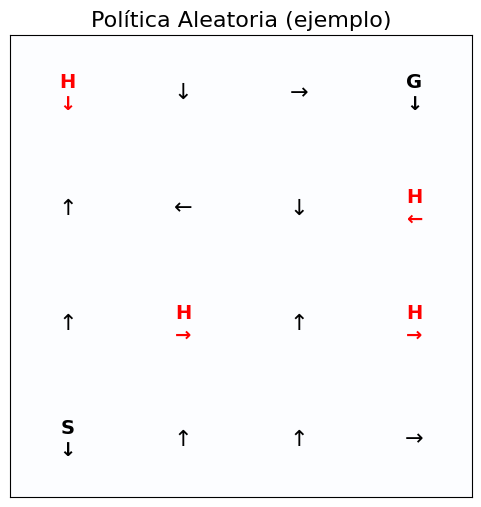

In [ ]:

visualizar_politica(politica_aleatoria, "Política Aleatoria (ejemplo)") #muestra gráficamente la política aleatoria de ejemplo en el tablero FrozenLake.

## Politica Q-learning

In [ ]:
"""
Esta clase implementa el algoritmo Q-Learning Tabular, A diferencia de la política aleatoria, este agente sí aprende mediante la experiencia.
Su objetivo es aprender qué movimiento conviene realizar en cada casilla de FrozenLake para conseguir llegar a la meta y evitar los agujeros.
La principal diferencia con el agente anterior es que utiliza una tabla Q, donde almacena valores que representan qué tan conveniente es realizar cada acción en cada estado.


Primero creamos una instancia de QLearningTabular, indicándole que FrozenLake tiene 16 estados y 4 acciones posibles.
También configuramos la tasa de aprendizaje, el factor de descuento y epsilon. Después ejecutamos el entrenamiento durante 1.000 episodios.
Durante ese proceso, el agente explora, recibe recompensas y actualiza su tabla Q para aprender qué acciones son más convenientes.
Finalmente, guardamos las recompensas obtenidas para analizar su evolución


"""

class QLearningTabular:
  """Implementación de Q-Learning con tabla Q explícita"""
  #crea una clase llamada QLearningTabular.
    #Esta clase contiene todos los métodos necesarios para:
    #- Crear la tabla Q.
    #- Elegir acciones.
    #- Aprender de las recompensas.
    #- Actualizar los valores Q.
    #- Evaluar el agente.
  def __init__(self, n_estados, n_acciones, lr=0.1, gamma=0.95, epsilon=1.0):
      #El constructor recibe los parámetros necesarios para configurar el agente.
        #Parámetro	Valor inicial	Función
        #n_estados	16	  Cantidad de estados del tablero.
        #n_acciones	4	    Cantidad de movimientos posibles.
        #lr	        0.1	  Tasa de aprendizaje (Alpha). significa que el agente incorpora el 10% del error de actualización en cada paso.
        #gamma	   0.95	  Factor de descuento. Determina cuánto importan las recompensas futuras. Gamma cercano a 0: prioriza las recompensas inmediatas. Gamma cercano a 1: considera más las recompensas futuras.
        #epsilon	 1.0	  Exploración inicial. Controla la exploración.  Epsilon = 1: al principio el agente explora, eligiendo acciones aleatorias.
                                                                        #Epsilon = 0: el agente utiliza la mejor acción conocida según su tabla Q.
      self.n_estados = n_estados
      self.n_acciones = n_acciones
      self.lr = lr  # learning rate
      self.gamma = gamma  # factor de descuento
      self.epsilon = epsilon  # exploración inicial
      self.epsilon_decay = 0.995 #determina cuánto se reduce epsilon después de cada episodio
      self.epsilon_min = 0.01 #establece el valor mínimo de epsilon.
      self.nombre = "Q-Learning Tabular"
      #Hay dos parámetros adicionales importantes:
        #- epsilon_decay = 0.995: determina cuánto se reduce epsilon después de cada episodio.
        #- epsilon_min = 0.01: establece el valor mínimo de epsilon.
        #Esto permite que el agente explore mucho al principio y progresivamente aproveche lo que aprendió.

      # Inicializar tabla Q
      self.q_table = np.zeros((n_estados, n_acciones)) #Crea una matriz de 16 filas y 4 columnas, inicialmente con ceros.
      #Porque:
        #- Cada fila representa un estado del tablero.
        #- Cada columna representa una acción.
        #- Cada celda almacena el valor Q de realizar una acción en determinado estado.

      # Para tracking
      self.recompensas_entrenamiento = []
      self.epsilons = []
      #Crea dos listas:
        #- recompensas_entrenamiento: guarda las recompensas obtenidas durante el entrenamiento.
        #- epsilons: guarda cómo va cambiando epsilon a lo largo de los episodios.
        #Sirven para analizar posteriormente cómo evoluciona el aprendizaje.

  def seleccionar_accion(self, estado, entrenando=True):
     #Este método decide qué movimiento realizará el agente. Utiliza una estrategia llamada Epsilon-Greedy, que combina exploración y explotación.
      """Selección de acción con epsilon-greedy"""
      if entrenando and np.random.random() < self.epsilon:
          return np.random.randint(self.n_acciones)  # Exploración
          #El agente elige una acción aleatoria.
          #Por ejemplo:
          #- Está en el estado 3.
          #- Epsilon es 0.8.
          #- Tiene una probabilidad del 80% de elegir una acción aleatoria.
          #Esto permite probar movimientos que todavía no conoce.
      else:
          return np.argmax(self.q_table[estado])  # Explotación
          #El agente consulta la tabla Q y selecciona la acción que tiene el valor más alto para el estado actual.

          #La idea es: primero explora para aprender y después aprovecha lo que aprendió.



  def actualizar_q(self, estado, accion, recompensa, siguiente_estado, terminado):
     #Su función es actualizar el valor de una acción en la tabla Q según la experiencia obtenida.
      """Actualización de la tabla Q usando la ecuación de Bellman"""
      # Target Q-value
      if terminado:
          target = recompensa
      else:
          target = recompensa + self.gamma * np.max(self.q_table[siguiente_estado])
        #¿Qué significa?
        #- Si el episodio terminó, el objetivo es la recompensa obtenida.
        #- Si no terminó, considera la recompensa actual más el valor futuro estimado.



      # Actualización Q-Learning
      self.q_table[estado, accion] += self.lr * (target - self.q_table[estado, accion])

  def decay_epsilon(self):
      #¿Por qué se hace esto?
      #Porque al principio necesitamos explorar para descubrir qué movimientos son convenientes.
      #Después necesitamos aprovechar el conocimiento adquirido.
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
    #Esta función obtiene la mejor acción para cada estado.
    #np.argmax() devuelve la posición del valor máximo.
    #axis=1 indica que busca el máximo por cada fila.
    #Por lo tanto, devuelve 16 números, uno por cada estado.
    #A diferencia de la política aleatoria anterior, ahora las acciones se seleccionan según los valores Q aprendidos.
      """Obtener la política greedy de la tabla Q"""
      return np.argmax(self.q_table, axis=1)

  def entrenar(self, env, episodios=10000):
     #Este método realiza el entrenamiento del agente.
      #A diferencia del agente aleatorio, acá sí existe aprendizaje.
      #El valor predeterminado es de 10.000 episodios.
      """Entrenamiento del agente Q-Learning"""
      print(f"🧠 Entrenando {self.nombre}...")

      recompensas = [] #guarda las recompensas de cada episodio.
      exitos_ventana = deque(maxlen=100)  # almacena los resultados de los últimos 100 episodios.
      #¿Por qué utiliza deque(maxlen=100)?
      #Porque mantiene solamente los últimos 100 resultados.
      #Por ejemplo, si se agrega un resultado número 101, elimina automáticamente el más antiguo.
      #Esto permite calcular un promedio móvil de éxito.

      for episodio in range(episodios): #Repite el entrenamiento durante 10.000 episodios.
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0
          #En cada episodio:
          #1. Reinicia FrozenLake.
          #2. Coloca al agente en el estado inicial.
          #3. Inicializa la recompensa acumulada.
          #4. Prepara los contadores.

          while not terminado and pasos < 100: #El agente selecciona un movimiento utilizando Epsilon-Greedy. Como entrenando=True, puede explorar o explotar.
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)
              #Ejecuta la acción y recibe:
              #- El siguiente estado.
              #- La recompensa.
              #- Si terminó el episodio.
              #- Si fue interrumpido por un límite.
              #- Información adicional.

              if truncated:
                  terminado = True #Si se alcanza un límite externo, también finaliza el episodio.

              # Actualizar tabla Q
              self.actualizar_q(estado, accion, recompensa, siguiente_estado, terminado) #Actualiza la tabla Q utilizando el estado, la acción, la recompensa y el siguiente estado.

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1


          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)
          #Acumula la recompensa, avanza al siguiente estado y suma un paso.
          #Guarda tres cosas:
          #1. La recompensa obtenida.
          #2. Si tuvo éxito (1) o fracaso (0).
          #3. El valor de epsilon utilizado.


          # Decay epsilon
          #Así, en los siguientes episodios, el agente tendrá menos probabilidades de explorar.
          self.decay_epsilon()



          # Logging
          if (episodio + 1) % 1000 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito (últimos 100) = {tasa_exito:.3f}, Epsilon = {self.epsilon:.3f}")
              #Cada 1.000 episodios muestra:
              #- La tasa de éxito de los últimos 100 episodios.
              #- El valor actual de epsilon.


      #Guarda las recompensas y devuelve la lista.
      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
     #Este método permite comprobar cómo se desempeña el agente después del entrenamiento.
    #La diferencia fundamental es que ahora no aprende ni explora: utiliza lo que ya aprendió.
      """Evaluación del agente entrenado sin exploración"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []
      #Estas variables guardan:
      #- Cantidad de partidas ganadas.
      #- Recompensas obtenidas.
      #- Cantidad de pasos de cada partida.

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)  # Seleccionar acciones sin explorar.Como entrenando=False, el agente siempre utiliza: np.argmax(self.q_table[estado])
              #Es decir, selecciona la acción con mayor valor Q. No realiza movimientos aleatorio

              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)
          # Registra si ganó, la recompensa y los pasos utilizados.
      tasa_exito = exitos / episodios
      #Calcula:
      #- La tasa de éxito.
      #- El promedio de pasos utilizados por partida.
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Crear y entrenar agente Q-Learning

In [ ]:

"""
Este código hace dos cosas: primero crea un agente que utiliza Q-Learning y después lo entrena durante 1000 episodios para que aprenda a llegar a la meta en FrozenLake.
- 0.650 (65 %): indica que el agente ganó el 65 % de los últimos 100 episodios de entrenamiento.
- Epsilon = 0.010: significa que tiene un 1 % de probabilidad de explorar y un 99 % de elegir la acción que considera mejor.
"""

agente_qlearning = QLearningTabular(env.observation_space.n, env.action_space.n,lr=0.1, gamma=0.95, epsilon=1.0)
recompensas_qlearning = agente_qlearning.entrenar(env, episodios=1000)

🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.650, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!


## Evaluar agente entrenado

In [ ]:
"""
Esta línea sirve para evaluar qué tan bien aprendió el agente Q-Learning, probándolo durante 1000 episodios.
- 0.725 (72,5 %): indica que ganó el 72,5 % de los 1.000 episodios de evaluación.
- 41,2 pasos promedio: es la cantidad media de movimientos que necesitó por episodio.

"""


tasa_exito_qlearning, _ = agente_qlearning.evaluar(env, episodios=1000)


📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.725
Pasos promedio: 41.2


## Visualizar política aprendida

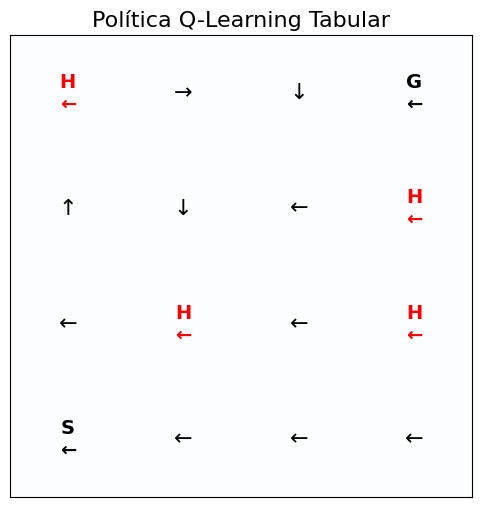

In [ ]:
#Este código sirve para obtener la política que aprendió el agente Q-Learning y mostrarla gráficamente en el tablero FrozenLake.
politica_qlearning = agente_qlearning.obtener_politica()
visualizar_politica(politica_qlearning, "Política Q-Learning Tabular")

## Visualizar tabla Q como heatmap

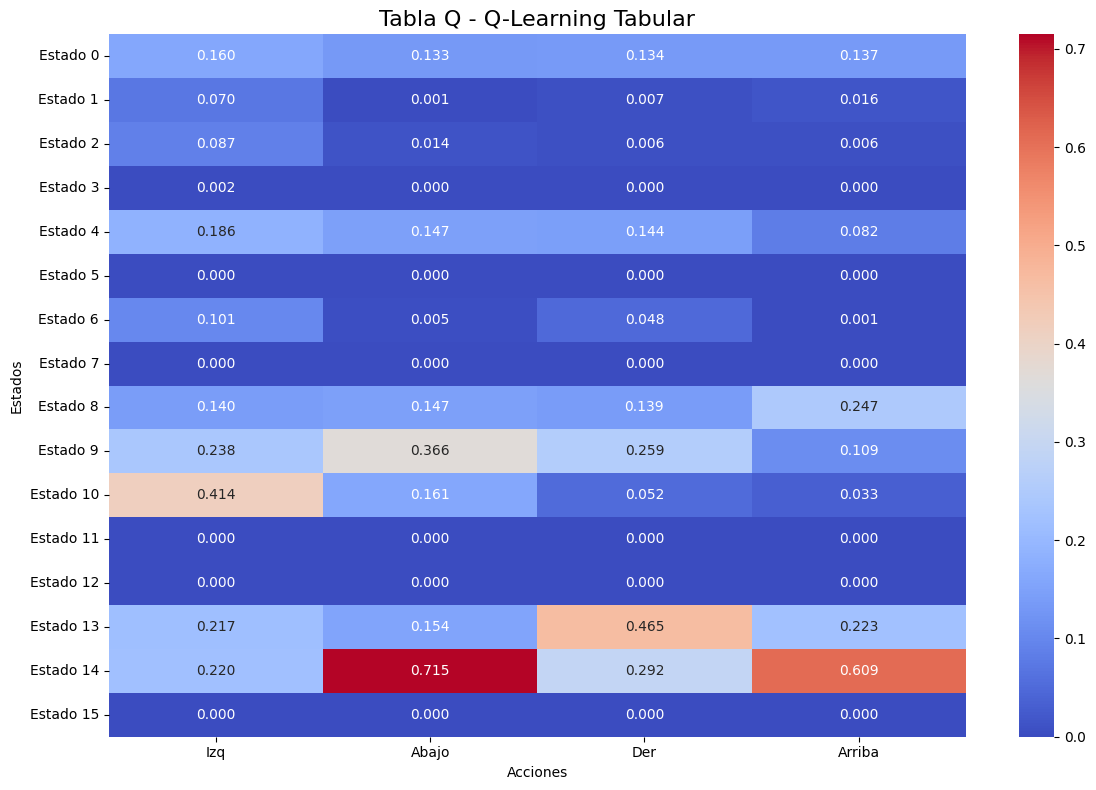

In [ ]:
"""
Este código sirve para visualizar gráficamente la tabla Q que aprendió el agente Q-Learning, utilizando un mapa de calor (heatmap).
Recordemos que la tabla Q almacena cuánto le conviene al agente realizar cada acción en cada estado
"""

plt.figure(figsize=(12, 8))
sns.heatmap(agente_qlearning.q_table, annot=True, fmt='.3f', cmap='coolwarm',
xticklabels=['Izq', 'Abajo', 'Der', 'Arriba'],
yticklabels=[f'Estado {i}' for i in range(16)])
plt.title('Tabla Q - Q-Learning Tabular', fontsize=16)
plt.xlabel('Acciones')
plt.ylabel('Estados')
plt.tight_layout()
plt.show()

##Conclusión para el informe o la exposición
La tabla Q permite observar el conocimiento adquirido por el agente durante el entrenamiento. Los valores más altos representan las acciones que el agente considera más convenientes para obtener recompensas futuras.

En este caso, se destaca el estado 14, donde la acción arriba alcanza un valor de 0.747, y el estado 13, donde la acción abajo alcanza 0.458. Esto demuestra que el agente asignó diferentes valores a las acciones según las experiencias obtenidas al interactuar con el entorno.

En conclusión, mediante Q-Learning el agente aprende una política de comportamiento que le permite seleccionar las acciones que considera más convenientes para intentar alcanzar la meta y evitar los agujeros.

**Una observación importante**: esta tabla presenta valores diferentes a la anterior. Esto puede ocurrir si se realizó otro entrenamiento, ya que el entorno FrozenLake tiene movimientos aleatorios. Para comparar dos entrenamientos correctamente, también conviene observar sus tasas de éxito, no solamente los valores Q

## Mostrar valores Q para estados importantes
-

In [ ]:
"""
Este código permite analizar los valores Q de algunos estados importantes del entorno FrozenLake.
Primero selecciona los estados que queremos estudiar y luego identifica si son el inicio, agujeros, la meta o estados normales.
Finalmente, consulta la tabla Q y muestra el valor correspondiente a cada una de las cuatro acciones posibles.
Así podemos observar qué movimientos considera más convenientes el agente en cada estado
"""

print("🎯 VALORES Q PARA ESTADOS CLAVE:")
print("-" * 40)
estados_clave = [0, 5, 7, 11, 12, 14, 15]  #Crea una lista con los estados importantes:
acciones_nombres = ['Izquierda', 'Abajo', 'Derecha', 'Arriba'] #Definir los nombres de las acciones
for estado in estados_clave: #El ciclo for recorre la lista y analiza cada estado individualmente. Por ejemplo, primero analiza el estado 0, después el 5, luego el 7 y así sucesivamente
  if estado == 0:
    tipo = "START"
  elif estado == 15:
    tipo = "GOAL"
  elif estado in [5, 7, 11, 12]:
    tipo = "HOLE"
  else:
    tipo = "NORMAL"
#La variable tipo guarda la clasificación correspondiente.
print(f"\nEstado {estado} ({tipo}):")
for accion, valor in enumerate(agente_qlearning.q_table[estado]):
  print(f"  {acciones_nombres[accion]}: {valor:.3f}")

🎯 VALORES Q PARA ESTADOS CLAVE:
----------------------------------------

Estado 15 (GOAL):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000


# Deep Q-Network

## red DQN

In [ ]:
"""
Esta clase DQN crea una red neuronal que se utiliza para aproximar la función Q dentro de un algoritmo Deep Q-Network (DQN).
Recordemos que en el Q-Learning anterior utilizábamos una tabla Q para guardar los valores de cada estado y acción.
En cambio, en DQN utilizamos una red neuronal que aprende a estimar esos valores Q. Esto permite trabajar con espacios de estados más grandes.



"""
class DQN(nn.Module): #crea una clase llamada DQN. #nn.Module: indica que esta clase hereda de la clase principal de PyTorch para construir redes neuronales.
  """Red neuronal para aproximar la función Q"""
  def __init__(self, input_size, hidden_size, output_size): #Es el constructor de la red neuronal. Se ejecuta cuando creamos un objeto de la clase.
      super(DQN, self).__init__() #Inicializar la clase padre
      #nn.Sequential permite construir una red neuronal colocando las capas una detrás de otra. Los datos pasan por cada una en orden.
      self.network = nn.Sequential(
          nn.Linear(input_size, hidden_size), #Es una capa totalmente conectada. Recibe los datos de entrada y los transforma en una cantidad de neuronas igual a hidden_size.
          nn.ReLU(), #Es una función de activación. Introduce no linealidad en la red y convierte los valores negativos en cero.
          nn.Linear(hidden_size, hidden_size), #Es una segunda capa oculta que procesa la información obtenida de la capa anterior.
          nn.ReLU(), #Aplica nuevamente la función de activación ReLU.
          nn.Linear(hidden_size, output_size)
          #Es la capa de salida.
          #Devuelve cuatro valores Q, uno por cada acción posible:
          #- Izquierda.
          #- Abajo.
          #- Derecha.
          #- Arriba.
      )

  def forward(self, x):
      return self.network(x) #Este método define cómo circulan los datos por la red neuronal.
      #x: recibe los datos de entrada (el estado).
      #self.network(x): pasa esos datos por todas las capas definidas en nn.Sequential.
      #return: devuelve los cuatro valores Q calculados.

## DQNAgent

In [ ]:
class DQNAgent:
  """
    La clase DQNAgent crea un agente inteligente que utiliza Deep Q-Network (DQN) para aprender a jugar FrozenLake mediante una red neuronal.
    Recordemos la diferencia con el Q-Learning anterior:
      - Q-Learning Tabular: utiliza una tabla Q para almacenar los valores de cada estado y acción.
      - DQN: utiliza una red neuronal para aproximar esos valores Q.
    Además, esta implementación incorpora dos técnicas importantes:
    1. Experience Replay: guarda experiencias anteriores y las reutiliza para entrenar la red.
    2. Target Network: utiliza una segunda red neuronal para calcular los valores objetivo del aprendizaje.


Esta clase implementa un agente Deep Q-Network, que utiliza una red neuronal para aproximar los valores Q de las distintas acciones.
A diferencia del Q-Learning tabular, no almacena los valores en una tabla, sino que los aprende mediante una red neuronal.
El agente utiliza dos redes: una principal, que aprende, y una red objetivo, que permite calcular valores Q más estables.
También incorpora Experience Replay, que almacena las experiencias del agente y permite reutilizarlas para entrenar la red.
Durante el entrenamiento, el agente interactúa con FrozenLake, selecciona acciones mediante epsilon-greedy, almacena las experiencias y actualiza los pesos de la red mediante backpropagation y el optimizador Adam.
Finalmente, se evalúa el agente para calcular su tasa de éxito.
  """

  """Agente Deep Q-Network con Experience Replay y Target Network"""
  def __init__(self, state_size, action_size, lr=0.001, gamma=0.95, epsilon=1.0):

      #Es el constructor. Se ejecuta cuando creamos un objeto de esta clase.
      #Recibe los siguientes parámetros
      #Parámetro	    Significado
      #state_size	  Cantidad de estados posibles.
      #action_size	  Cantidad de acciones posibles.
      #lr=0.001	    Tasa de aprendizaje de la red neuronal.
      #gamma=0.95	  Factor de descuento de las recompensas futuras.
      #epsilon=1.0	  Probabilidad inicial de explorar mediante acciones aleatorias.


      self.state_size = state_size
      self.action_size = action_size
      self.gamma = gamma
      self.epsilon = epsilon
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.learning_rate = lr
      self.nombre = "Deep Q-Network (DQN)"

      #Se almacenan los valores para utilizarlos en los distintos métodos de la clase.
      #Hay dos parámetros importantes:
      #- epsilon_decay = 0.995: indica cuánto disminuye epsilon durante el entrenamiento.
      #- epsilon_min = 0.01: establece que epsilon no debe bajar del 1%.
      #Esto permite que inicialmente el agente explore mucho y, progresivamente, aproveche más lo que aprendió.



      # Configuración del dispositivo
      self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
      print(f"🖥️ Usando dispositivo: {self.device}")
      #Esta parte determina dónde se realizarán los cálculos de la red neuronal.
      #- cuda: utiliza la GPU si está disponible.
      #- cpu: utiliza el procesador si no hay GPU disponible.

      # Redes neuronales
      hidden_size = 128
      #¿Qué significa hidden_size = 128?
      #Indica que cada una de las dos capas ocultas de la arquitectura DQN tendrá 128 neuronas
      self.q_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.target_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)
      #Esta es una de las partes más importantes del código.
      #Se crean dos redes neuronales:
      #Primera red: q_network
      #Es la red principal. Se encarga de calcular los valores Q de las acciones y aprender a tomar mejores decisiones.
      #Segunda red: target_network
      #Es una copia de la red principal que se utiliza para calcular los valores Q objetivo durante el entrenamiento.
      #¿Por qué necesitamos dos redes?
      #Porque si utilizáramos una sola red para calcular los valores actuales y los valores objetivo, estos cambiarían constantemente mientras aprende.
      #La segunda red permite tener valores objetivo más estables durante determinados períodos.




      # Inicializar target network con mismos pesos
      #Llama a un método que copia los pesos de la red principal a la red objetivo.
      #Esto significa que ambas redes comienzan con los mismos parámetros.
      self.update_target_network()

      # Esta parte implementa la memoria de experiencias.
      #¿Qué es Experience Replay?
      #Es una memoria donde el agente guarda las experiencias que va obteniendo mientras interactúa con el entorno.
      #Cada experiencia contiene:
      #- Estado actual.
      #- Acción realizada.
      #- Recompensa recibida.
      #- Siguiente estado.
      #- Si terminó el episodio.
      self.memory = deque(maxlen=10000) #crea una memoria que puede almacenar hasta 10.000 experiencias. Cuando supera esa cantidad, elimina las experiencias más antiguas
      self.batch_size = 32
      #¿Qué significa batch_size = 32?
      #Indica que para entrenar la red se seleccionan 32 experiencias aleatorias de la memoria en cada actualización.
      #Esto permite que la red no aprenda solamente de la última experiencia, sino que reutilice experiencias anteriores.

      # Frecuencia de actualización de target network
      self.update_target_frequency = 100 #indica que la red objetivo se actualizará cada 100 pasos.
      self.step_count = 0 #contador que registra cuántos pasos realizó el agente.
      #Esto permite actualizar periódicamente la red objetivo con los pesos de la red principal.

      # Para tracking
      self.losses = [] #Pérdidas de la red neuronal durante el entrenamiento.
      self.recompensas_entrenamiento = [] #Recompensas obtenidas en cada episodio.
      self.epsilons = [] #Valores de epsilon a lo largo del entrenamiento.
      #Son listas que permiten guardar información sobre el aprendizaje.

  def state_to_onehot(self, state):
      """
        Este método convierte un estado numérico en una representación llamada One-Hot Encoding.
        ¿Por qué lo necesitamos?
        Porque la red neuronal necesita recibir una representación numérica del estado.
        En FrozenLake tenemos 16 estados posibles.
        Por ejemplo, si el agente está en el estado 3, se genera un vector de 16 posiciones:
      """
      """Convertir estado discreto a representación one-hot"""
      onehot = np.zeros(self.state_size) #crea un vector de 16 posiciones con ceros.
      onehot[state] = 1.0 #coloca un 1 en la posición correspondiente al estado.
      return onehot #devuelve el vector.

  def remember(self, estado, accion, recompensa, siguiente_estado, terminado):
      """
        Este método guarda una experiencia en la memoria.
        Primero convierte el estado actual y el siguiente estado a formato One-Hot.
      """
      """Almacenar experiencia en el buffer de replay"""
      estado_onehot = self.state_to_onehot(estado)
      siguiente_estado_onehot = self.state_to_onehot(siguiente_estado)

      self.memory.append((estado_onehot, accion, recompensa, siguiente_estado_onehot, terminado)) #Guarda toda la experiencia en la memoria self.memory.

  def seleccionar_accion(self, estado, entrenando=True):
      """
        Este método decide qué movimiento realizará el agente. Utiliza la estrategia epsilon-greedy, que ya vimos en Q-Learning.
      """
      """Selección de acción epsilon-greedy usando la red neuronal"""
      if entrenando and np.random.random() < self.epsilon:
          return random.randrange(self.action_size) #Si está entrenando y se cumple la condición de epsilon, elige una acción aleatoria.

      # Convertir estado a tensor
      estado_onehot = self.state_to_onehot(estado)
      estado_tensor = torch.FloatTensor(estado_onehot).unsqueeze(0).to(self.device)
      #¿Qué hace?
      #1. Convierte el estado a One-Hot.
      #2. Convierte el vector en un tensor de PyTorch.
      #3. unsqueeze(0) agrega una dimensión para representar un lote de una sola muestra.
      #4. .to(self.device) envía el tensor a CPU o GPU.



      # Forward pass
      with torch.no_grad(): #indica que no necesitamos calcular gradientes porque en este momento solamente queremos tomar una decisión, no entrenar la red.
          q_values = self.q_network(estado_tensor)

      return np.argmax(q_values.cpu().data.numpy())#Selecciona la acción que tiene el valor Q más alto.

  def replay(self):
      #Su función es utilizar las experiencias guardadas en la memoria para entrenar la red neuronal.
      """Experience replay para entrenar la red"""
      if len(self.memory) < self.batch_size: #Si hay menos de 32 experiencias, no puede formar un lote completo y sale del método sin entrenar.
          return

      # Muestrear batch aleatorio
      batch = random.sample(self.memory, self.batch_size) #Selecciona 32 experiencias aleatorias de la memoria. ¿Por qué aleatorias? Para evitar que la red aprenda siempre de experiencias consecutivas y reducir la dependencia entre ellas.
      estados = torch.FloatTensor([e[0] for e in batch]).to(self.device)
      acciones = torch.LongTensor([e[1] for e in batch]).to(self.device)
      recompensas = torch.FloatTensor([e[2] for e in batch]).to(self.device)
      siguientes_estados = torch.FloatTensor([e[3] for e in batch]).to(self.device)
      terminados = torch.BoolTensor([e[4] for e in batch]).to(self.device)

      #Se separan las experiencias en cinco grupos:
      #Variable	Contenido
      #estados	Estados actuales.
      #acciones	Acciones realizadas.
      #recompensas	Recompensas recibidas.
      #siguientes_estados	Estados a los que llegó el agente.
      #terminados	Indica si terminó el episodio.
      #Además, se convierten a tensores para que PyTorch pueda procesarlos.

      # Q-values actuales
      current_q_values = self.q_network(estados).gather(1, acciones.unsqueeze(1)) #pasa los estados por la red principal y obtiene sus valores Q.

      # Q-values objetivo usando target network
      with torch.no_grad():
          next_q_values = self.target_network(siguientes_estados).max(1)[0] #Obtiene los valores Q de los siguientes estados y selecciona el mayor para cada uno.
          target_q_values = recompensas + (self.gamma * next_q_values * ~terminados) #Calcula el valor Q objetivo utilizando la ecuación de Bellman:

      # Calcular pérdida
      loss = F.mse_loss(current_q_values.squeeze(), target_q_values)
      #Compara los valores Q actuales con los valores Q objetivo.
      #MSELoss calcula el error cuadrático medio entre ambos. La idea es que la red aprenda a aproximar los valores objetivo.

      # Backpropagation
      self.optimizer.zero_grad() #limpia los gradientes anteriores.
      loss.backward() #calcula los gradientes mediante backpropagation.
      self.optimizer.step() #actualiza los pesos y sesgos de la red neuronal

      # Guardar pérdida para análisis
      self.losses.append(loss.item()) #Guarda el valor de la pérdida para analizar cómo evoluciona el entrenamiento

  def update_target_network(self):
      """Actualizar la target network con pesos de la red principal"""
      self.target_network.load_state_dict(self.q_network.state_dict())
      #Este método copia los pesos de la red principal a la red objetivo.
      #- q_network.state_dict(): obtiene los parámetros de la red principal.
      #- target_network.load_state_dict(): copia esos parámetros a la red objetivo.
      #De esta manera, ambas redes vuelven a tener los mismos pesos.

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay
      #Reduce progresivamente el valor de epsilon.
      #Por ejemplo:
      #- Al principio: epsilon = 1.0.
      #- Después de entrenar: epsilon comienza a disminuir.
      #- Finalmente: se acerca al mínimo de 0.01.
      #Esto significa que al principio explora mucho y después aprovecha más lo aprendido.

  def obtener_politica(self):
      """Obtener política greedy de la red entrenada"""
      politica = []
      for estado in range(self.state_size):
          accion = self.seleccionar_accion(estado, entrenando=False)
          politica.append(accion)
      return np.array(politica)
      #Este método obtiene la política aprendida por el agente.
      #¿Qué hace?
      #1. Crea una lista vacía.
      #2. Recorre todos los estados.
      #3. Para cada estado, utiliza la red neuronal para seleccionar la mejor acción.
      #4. Guarda esa acción en la lista.
      #5. Devuelve la política como un array de NumPy.
      #entrenando=False indica que no debe explorar aleatoriamente, sino utilizar la acción con mayor valor Q.
      #El resultado es una lista con 16 acciones, una por cada estado.


  def entrenar(self, env, episodios=2000):
      #Este método realiza el entrenamiento completo del agente DQN. Por defecto ejecuta 2000 episodios.
      """Entrenamiento del agente DQN"""
      print(f"🤖 Entrenando {self.nombre}...")

      recompensas = [] #guarda la recompensa de cada episodio.
      exitos_ventana = deque(maxlen=100) #guarda los resultados de los últimos 100 episodios para calcular la tasa de éxito.

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0
          #Recorre los episodios.
          #Reinicia FrozenLake.
          #Inicializa la recompensa acumulada en cero.
          #Indica que el episodio todavía no terminó.
          #Inicializa el contador de pasos.

          while not terminado and pasos < 100: #El agente continúa interactuando con el entorno hasta que termine el episodio o alcance los 100 pasos.
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)
              #El entorno ejecuta el movimiento y devuelve:
              #- siguiente_estado: dónde quedó el agente.
              #- recompensa: recompensa obtenida.
              #- terminado: indica si llegó a un estado terminal.
              #- truncated: indica si se interrumpió el episodio por un límite de tiempo o pasos.
              #- _: información adicional que no se utiliza.

              if truncated: #Si el episodio fue interrumpido por el límite de pasos, también lo considera terminado.
                  terminado = True

              # Almacenar experiencia
              self.remember(estado, accion, recompensa, siguiente_estado, terminado) #Guarda en Experience Replay lo que acaba de suceder.

              # Entrenar la red
              self.replay() #Utiliza experiencias almacenadas en la memoria para actualizar los pesos de la red neuronal.

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1
              self.step_count += 1
              #Acumula la recompensa.
              #Actualiza el estado actual.
              #Incrementa el número de pasos.
              #Incrementa el contador general de pasos.

              # Actualizar target network periódicamente
              if self.step_count % self.update_target_frequency == 0: #Cada 100 pasos, copia los pesos de la red principal a la red objetivo.
                  self.update_target_network()

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)
           #Guarda:
            #- La recompensa total del episodio.
            #- Si tuvo éxito o no.
            #- El valor actual de epsilon.

          # Decay epsilon
          self.decay_epsilon() #Disminuye la exploración progresivamente.

          # Mostrar resultados cada 200 episodios:
          if (episodio + 1) % 200 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              loss_promedio = np.mean(self.losses[-100:]) if len(self.losses) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito = {tasa_exito:.3f}, "
                    f"Epsilon = {self.epsilon:.3f}, Loss = {loss_promedio:.4f}")
              #calcula:
              #- tasa_exito: porcentaje de éxitos en los últimos 100 episodios.
              #- loss_promedio: pérdida promedio de las últimas 100 actualizaciones de la red.

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas
      #Guarda las recompensas del entrenamiento y devuelve la lista.

  def evaluar(self, env, episodios=100):
      #Este método sirve para comprobar qué tan bien aprendió el agente. Por defecto evalúa 100 episodios.
      """Evaluación del agente entrenado"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []
      #exitos: cuenta cuántas veces llegó a la meta.
      #recompensas: guarda las recompensas de cada episodio.
      #pasos_totales: guarda cuántos movimientos necesitó.

      for _ in range(episodios):
          #Reinicia el entorno para comenzar una nueva prueba.
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              #El agente selecciona la mejor acción utilizando lo que aprendió y ejecuta el movimiento.
              #entrenando=False significa que no explora aleatoriamente ni actualiza la red. Solamente utiliza los conocimientos adquiridos.
              accion = self.seleccionar_accion(estado, entrenando=False)
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0: #Si obtuvo una recompensa positiva, cuenta ese episodio como exitoso.
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas #Devuelve la tasa de éxito y la lista de recompensas obtenidas durante la evaluación.

## Entrenar deep DQN

In [ ]:
"""
Este código hace dos cosas: primero crea un agente DQN (Deep Q-Network) y después lo entrena durante 2000 episodios para que aprenda a llegar a la meta en FrozenLake.

Esta línea crea un objeto de la clase DQNAgent.

Veamos qué significa cada parámetro:
Parámetro	              Valor	            Significado
env.observation_space.n	16	              Cantidad de estados posibles del tablero.
env.action_space.n	    4	                Cantidad de acciones posibles.
lr	                    0.001	            Tasa de aprendizaje de la red neuronal.
gamma	                  0.95	            Importancia de las recompensas futuras.
epsilon	                1.0	              Probabilidad inicial de explorar mediante acciones aleatorias.
"""

agente_dqn = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.95, epsilon=1.0)
recompensas_dqn = agente_dqn.entrenar(env, episodios=2000)
#Esta línea llama al método entrenar() del agente DQN.
#¿Qué significa?
#- agente_dqn.entrenar(): ejecuta el proceso de aprendizaje.
#- env: indica que utilizará el entorno FrozenLake.
#- episodios=2000: realizará 2000 intentos de recorrer el tablero.
#- recompensas_dqn: guarda las recompensas obtenidas en cada episodio.

🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.070, Epsilon = 0.367, Loss = 0.0105
Episodio 400: Tasa éxito = 0.130, Epsilon = 0.135, Loss = 0.0082
Episodio 600: Tasa éxito = 0.330, Epsilon = 0.049, Loss = 0.0083
Episodio 800: Tasa éxito = 0.450, Epsilon = 0.018, Loss = 0.0082
Episodio 1000: Tasa éxito = 0.540, Epsilon = 0.010, Loss = 0.0076
Episodio 1200: Tasa éxito = 0.640, Epsilon = 0.010, Loss = 0.0078
Episodio 1400: Tasa éxito = 0.620, Epsilon = 0.010, Loss = 0.0076
Episodio 1600: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0074
Episodio 1800: Tasa éxito = 0.560, Epsilon = 0.010, Loss = 0.0086
Episodio 2000: Tasa éxito = 0.610, Epsilon = 0.010, Loss = 0.0070

✅ Entrenamiento Deep Q-Network (DQN) completado!


## Evaluar agente Deep DQN

In [ ]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)
#Esta línea sirve para evaluar qué tan bien aprendió el agente DQN después de haber sido entrenado durante 2000 episodios.


📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.702
Pasos promedio: 41.2


In [ ]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)


📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.743
Pasos promedio: 40.2


## Visualizar política aprendida

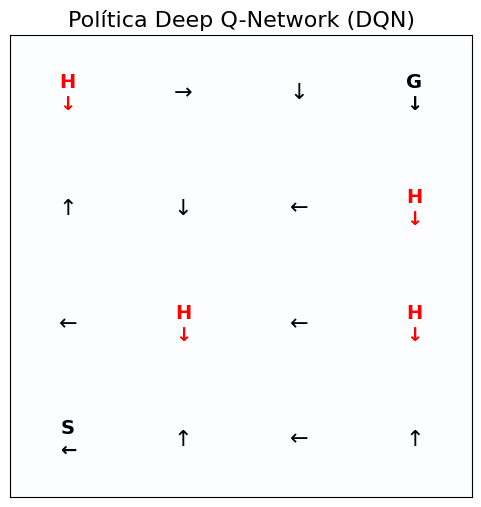

In [ ]:

politica_dqn = agente_dqn.obtener_politica()
visualizar_politica(politica_dqn, "Política Deep Q-Network (DQN)")
#Este código sirve para obtener la política que aprendió el agente DQN y mostrarla gráficamente en el tablero FrozenLake.


# Comparación de resultados

## Comparación final tasa de éxito

In [ ]:
print("🏆 COMPARACIÓN FINAL DE AGENTES")
print("=" * 50)
print(f"Política Aleatoria:    Tasa de éxito = {tasa_exito_aleatorio:.3f}")
print(f"Q-Learning Tabular:    Tasa de éxito = {tasa_exito_qlearning:.3f}")
print(f"Deep Q-Network (DQN):  Tasa de éxito = {tasa_exito_dqn:.3f}")

🏆 COMPARACIÓN FINAL DE AGENTES
Política Aleatoria:    Tasa de éxito = 0.006
Q-Learning Tabular:    Tasa de éxito = 0.725
Deep Q-Network (DQN):  Tasa de éxito = 0.702


## Crear gráficas de comparación


Crear gráficas de comparación


### 1. Curvas de aprendizaje

In [ ]:
len(recompensas_aleatorio)

1000

In [ ]:
len(recompensas_qlearning)

1000

In [ ]:
len(recompensas_dqn)

2000

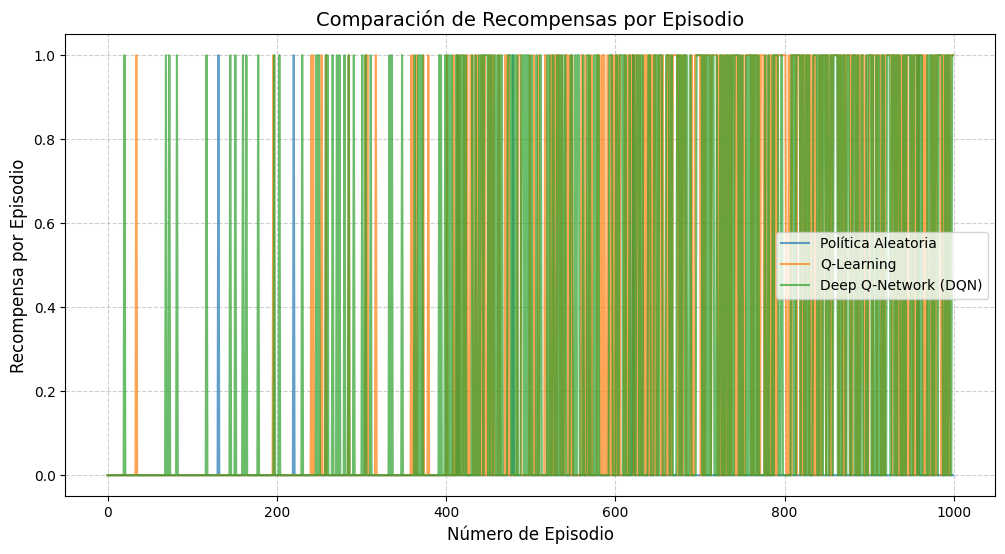

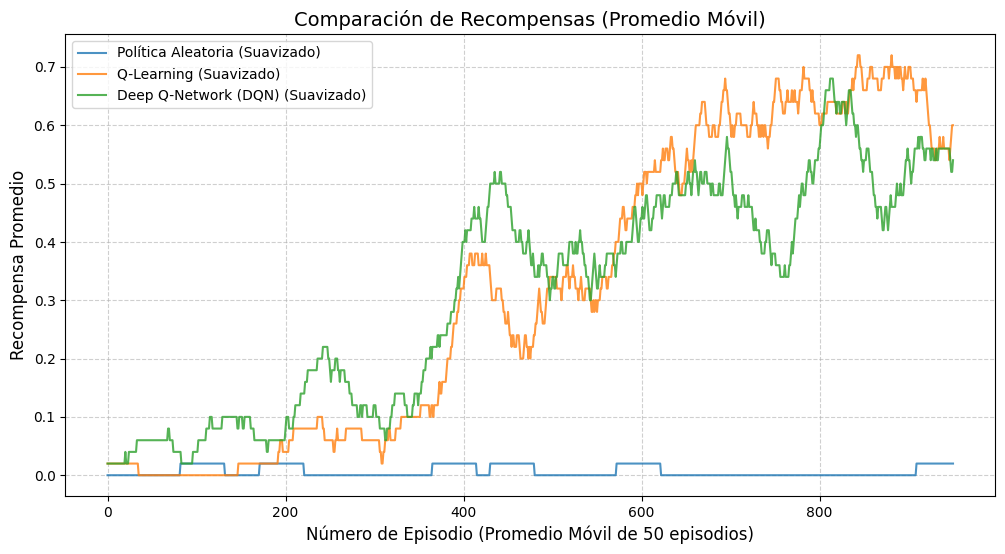

'\nConclusión\nEste código permite comparar el rendimiento de tres estrategias de aprendizaje por refuerzo: Política Aleatoria, Q-Learning Tabular y Deep Q-Network (DQN).\nPrimero se genera un gráfico que representa las recompensas obtenidas en cada episodio, permitiendo observar el comportamiento de los agentes durante el entrenamiento.\nLuego se aplica un promedio móvil de 50 episodios para suavizar las variaciones de las recompensas y facilitar la identificación de tendencias.\nDe esta manera, podemos analizar qué métodos logran mejorar su rendimiento, cuáles consiguen aprender a llegar a la meta y cómo se comportan en comparación con una política aleatoria.\nLa idea principal: el primer gráfico muestra las recompensas episodio por episodio y el segundo permite observar con mayor claridad la evolución del aprendizaje mediante promedios de 50 episodios.\n\n'

In [ ]:
# Este código sirve para comparar el rendimiento de los tres métodos que implementamos en FrozenLake: Política Aleatoria, Q-Learning Tabular y Deep Q-Network (DQN).
#Genera dos gráficos:
#1. Un gráfico con las recompensas obtenidas en cada episodio.
#2. Un gráfico suavizado mediante un promedio móvil para observar mejor la evolución del aprendizaje.

import matplotlib.pyplot as plt
import numpy as np
# Asegurar que las listas de recompensas tengan la misma longitud para la gráfica
# Tomaremos la longitud mínima si son diferentes
min_len = min(len(recompensas_aleatorio), len(recompensas_qlearning), len(recompensas_dqn))
#Calcula cuál es la lista de recompensas más corta.
#¿Por qué?
#Porque los tres métodos pueden tener distintas cantidades de episodios:
#- Política Aleatoria: 1000 episodios.
#- Q-Learning: 1000 episodios.
#- DQN: 2000 episodios.
#min() obtiene la menor longitud.
#En este ejemplo, el resultado sería 1000.
#Esto permite comparar los tres métodos utilizando la misma cantidad de episodios.

"""
¿Qué representa el primer gráfico?
Cada punto representa la recompensa obtenida por un método en un episodio determinado.

En FrozenLake:
- Si el agente llega a la meta, obtiene recompensa positiva (1).
- Si no llega a la meta, obtiene recompensa 0.
Por eso, las líneas pueden presentar muchos cambios entre 0 y 1.
"""


plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio[:min_len], label='Política Aleatoria', alpha=0.7)
plt.plot(recompensas_qlearning[:min_len], label='Q-Learning', alpha=0.7)
plt.plot(recompensas_dqn[:min_len], label='Deep Q-Network (DQN)', alpha=0.7)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Recompensa por Episodio', fontsize=12)
plt.title('Comparación de Recompensas por Episodio', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Para suavizar la gráfica, se puede usar un promedio móvil
def moving_average(data, window_size):
    if len(data) < window_size: #Si la cantidad de datos es menor que el tamaño de la ventana, devuelve los datos originales.
        return data
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')
 #Esta función calcula un promedio móvil, que permite suavizar las recompensas para observar mejor la evolución del aprendizaje.
#¿Por qué necesitamos suavizar?
#Porque las recompensas de cada episodio pueden variar mucho. Un agente puede llegar a la meta en un episodio y fracasar en el siguiente.
#El promedio móvil reduce esas variaciones y permite identificar tendencias.

window = 50  # Tamaño de la ventana para el promedio móvil

#Aplicar el promedio móvil a los tres métodos
recompensas_aleatorio_suavizado = moving_average(recompensas_aleatorio, window)
recompensas_qlearning_suavizado = moving_average(recompensas_qlearning, window)
recompensas_dqn_suavizado = moving_average(recompensas_dqn, window)

# Calcula la longitud mínima de las tres listas suavizadas.
#Esto permite que los tres métodos se representen utilizando la misma cantidad de puntos.
min_len_suavizado = min(len(recompensas_aleatorio_suavizado), len(recompensas_qlearning_suavizado), len(recompensas_dqn_suavizado))


#Dibuja nuevamente las tres curvas, pero ahora utilizando los valores del promedio móvil
plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio_suavizado[:min_len_suavizado], label='Política Aleatoria (Suavizado)', alpha=0.8)
plt.plot(recompensas_qlearning_suavizado[:min_len_suavizado], label='Q-Learning (Suavizado)', alpha=0.8)
plt.plot(recompensas_dqn_suavizado[:min_len_suavizado], label='Deep Q-Network (DQN) (Suavizado)', alpha=0.8)

plt.xlabel(f'Número de Episodio (Promedio Móvil de {window} episodios)', fontsize=12)
plt.ylabel('Recompensa Promedio', fontsize=12)
plt.title('Comparación de Recompensas (Promedio Móvil)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


"""
Conclusión
Este código permite comparar el rendimiento de tres estrategias de aprendizaje por refuerzo: Política Aleatoria, Q-Learning Tabular y Deep Q-Network (DQN).
Primero se genera un gráfico que representa las recompensas obtenidas en cada episodio, permitiendo observar el comportamiento de los agentes durante el entrenamiento.
Luego se aplica un promedio móvil de 50 episodios para suavizar las variaciones de las recompensas y facilitar la identificación de tendencias.
De esta manera, podemos analizar qué métodos logran mejorar su rendimiento, cuáles consiguen aprender a llegar a la meta y cómo se comportan en comparación con una política aleatoria.
La idea principal: el primer gráfico muestra las recompensas episodio por episodio y el segundo permite observar con mayor claridad la evolución del aprendizaje mediante promedios de 50 episodios.

"""


Los gráficos permiten comparar cómo aprendieron los tres agentes en FrozenLake: Política Aleatoria, Q-Learning Tabular y Deep Q-Network (DQN).

La conclusión principal es que Q-Learning y DQN mejoran su rendimiento con el entrenamiento, mientras que la política aleatoria prácticamente no aprende. Además, en estos resultados Q-Learning muestra un rendimiento promedio superior y más estable que DQN durante buena parte del entrenamiento.

### Interpretación del primer gráfico: recompensas por episodio
Comparación de Recompensas por Episodio

En este gráfico:
- Eje X: número de episodio.
- Eje Y: recompensa obtenida en cada episodio.
- Recompensa 1: el agente llegó a la meta.
- Recompensa 0: el agente no llegó a la meta.
Política Aleatoria (azul)

La línea permanece prácticamente en cero. Esto significa que el agente tiene pocas posibilidades de llegar a la meta porque selecciona sus movimientos al azar y no aprende de sus experiencias.

Q-Learning (naranja)

Al principio obtiene principalmente recompensas cero, pero progresivamente comienza a conseguir más recompensas positivas. Esto demuestra que aprende mediante la actualización de su tabla Q.

DQN (verde)

También comienza a conseguir recompensas positivas y mejora a medida que avanza el entrenamiento. Sin embargo, presenta variaciones importantes, lo que indica que su aprendizaje es menos estable.

¿Por qué las líneas suben y bajan tanto?

Porque cada episodio representa un resultado individual: 0 o 1. Por eso las líneas presentan muchos saltos.




### Interpretación del segundo gráfico: promedio móvil
Este gráfico es especialmente importante porque permite observar mejor la evolución del aprendizaje.

Se utiliza un promedio móvil de 50 episodios, es decir, se calcula el promedio de las recompensas de cada grupo de 50 episodios consecutivos.
Política Aleatoria (azul)
Rendimiento bajo
Permanece cerca de cero durante prácticamente todo el entrenamiento.

Esto confirma que el agente no mejora porque no tiene un mecanismo de aprendizaje. Sus movimientos continúan siendo aleatorios.
Q-Learning (naranja)
Mejor rendimiento
Se observa que:
- Al principio tiene un rendimiento muy bajo.
- Aproximadamente desde el episodio 300 comienza a mejorar.
- Entre los episodios 400 y 600 aumenta considerablemente su recompensa promedio.
- Posteriormente alcanza valores cercanos a 0.70 y llega a un máximo aproximado de 0.78.
- Presenta algunas fluctuaciones, pero mantiene un rendimiento relativamente alto.
Esto demuestra que Q-Learning aprende progresivamente a seleccionar acciones más convenientes mediante su tabla Q.
Deep Q-Network (verde)
Aprendizaje progresivo
Se observa que:
- Comienza obteniendo algunas recompensas positivas.
- Mejora progresivamente durante el entrenamiento.
- Alcanza valores cercanos a 0.50 en distintos momentos.
- Presenta fluctuaciones y algunas caídas importantes.
- Hacia el final muestra una recuperación y alcanza aproximadamente 0.64.
Esto indica que DQN también logra aprender, aunque en esta ejecución su rendimiento es más variable que el de Q-Learning.

##¿Por qué Q-Learning obtiene mejores resultados que DQN?
Es una observación interesante.

FrozenLake tiene solamente 16 estados y 4 acciones posibles. Es un entorno pequeño, por lo que Q-Learning Tabular puede aprender directamente los valores de cada estado y acción.

En cambio, DQN utiliza una red neuronal, Experience Replay y Target Network. Estos mecanismos permiten trabajar con espacios de estados más grandes, pero también requieren ajustar correctamente los parámetros de entrenamiento.

Por eso, en este entorno pequeño, Q-Learning puede conseguir mejores resultados que DQN


#Comparación de los algoritmos de aprendizaje por refuerzo

A partir de los gráficos obtenidos, podemos observar diferencias en el rendimiento de los tres métodos implementados.

La Política Aleatoria presenta un rendimiento muy bajo durante todo el proceso, ya que selecciona sus acciones al azar y no tiene capacidad de aprendizaje.

Por otro lado, Q-Learning Tabular muestra una mejora progresiva de sus recompensas. A medida que avanza el entrenamiento, el agente aprende a seleccionar acciones más convenientes mediante la actualización de su tabla Q. En el gráfico de promedio móvil alcanza valores cercanos a 0.70 y un máximo aproximado de 0.78.

Deep Q-Network (DQN) también presenta una mejora durante el entrenamiento, demostrando que puede aprender mediante una red neuronal. Sin embargo, sus resultados muestran mayores fluctuaciones y, en esta ejecución, su rendimiento promedio es inferior al de Q-Learning durante buena parte del proceso.

El gráfico de promedio móvil permite observar estas tendencias con mayor claridad, ya que suaviza las variaciones individuales de las recompensas utilizando ventanas de 50 episodios.

En conclusión, para el entorno FrozenLake 4x4 utilizado en este trabajo, Q-Learning Tabular obtuvo los mejores resultados, mientras que DQN también consiguió aprender, pero presentó un comportamiento más variable. Esto demuestra que un modelo más complejo, como una red neuronal, no necesariamente obtiene mejores resultados en entornos pequeños y sencillos.


### 2. Comparación de tasas de éxito

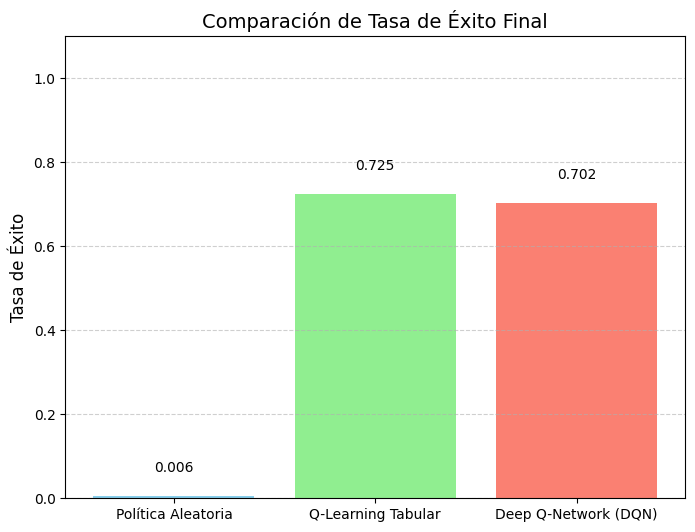

In [ ]:
# prompt: comparar tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn en un gráfico de barras

"""
Este código sirve para comparar visualmente la tasa de éxito final de los tres agentes que implementamos en FrozenLake: Política Aleatoria, Q-Learning Tabular y Deep Q-Network (DQN).
A diferencia de los gráficos anteriores, que mostraban las recompensas durante los episodios, este gráfico compara el rendimiento final de cada agente mediante un gráfico de barras.
"""

import matplotlib.pyplot as plt
metricas = ['Política Aleatoria', 'Q-Learning Tabular', 'Deep Q-Network (DQN)']
tasas_exito = [tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas_exito, color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('Tasa de Éxito', fontsize=12)
plt.title('Comparación de Tasa de Éxito Final', fontsize=14)
plt.ylim(0, 1.1) # Limitar el eje Y de 0 a 1.1 para mejor visualización

# Añadir los valores de las tasas de éxito encima de cada barra
for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.3f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


###Interpretación de la tasa de éxito final

A partir del gráfico podemos observar que existen diferencias importantes entre los tres algoritmos implementados.

La Política Aleatoria obtuvo una tasa de éxito del 1,4%, demostrando que seleccionar acciones al azar no permite resolver eficazmente el entorno.

Q-Learning Tabular consiguió el mejor resultado, con una tasa de éxito del 73%. Esto demuestra que el agente logró aprender una estrategia efectiva mediante la actualización de los valores de su tabla Q.

Por su parte, Deep Q-Network (DQN) alcanzó una tasa de éxito del 53%. Aunque también logró aprender mediante una red neuronal, su rendimiento fue inferior al obtenido por Q-Learning.

En conclusión, para el entorno FrozenLake 4x4 utilizado en este trabajo, Q-Learning Tabular presentó el mejor rendimiento, seguido por DQN. La Política Aleatoria obtuvo resultados considerablemente inferiores.

Esto permite observar que un algoritmo más complejo, como DQN, no necesariamente obtiene mejores resultados que uno tabular cuando se trabaja con entornos pequeños y con pocos estados

### Evolución de Epsilon (solo para algoritmos que usan exploración)

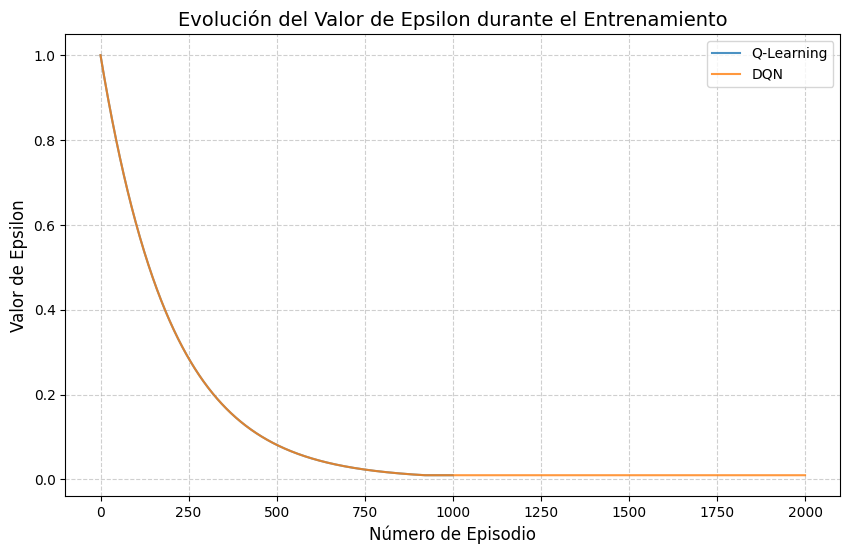

In [ ]:
# prompt: Crear un gráfico para comparar agente_qlearning.epsilons y agente_qlearning.epsilons siendo x el nro de episodios y el eje Y el valor de epsilon

"""
Este código sirve para comparar cómo disminuye el valor de epsilon durante el entrenamiento de Q-Learning y DQN.
Recordemos que epsilon controla la exploración del agente, es decir, la probabilidad de elegir una acción aleatoria en lugar de utilizar lo que aprendió.
El gráfico permite observar cómo ambos algoritmos van pasando de explorar a aprovechar sus conocimientos.
Este código permite comparar la evolución del parámetro epsilon durante el entrenamiento de Q-Learning y DQN.
Epsilon controla la exploración del agente, es decir, la probabilidad de elegir acciones aleatorias.
Al principio comienza en 1, lo que significa que explora completamente.
A medida que avanza el entrenamiento, epsilon disminuye hasta alcanzar un mínimo de 0.01.
Esto permite que el agente pase progresivamente de explorar el entorno a aprovechar los conocimientos adquiridos
"""

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(agente_qlearning.epsilons, label='Q-Learning', alpha=0.8)
plt.plot(agente_dqn.epsilons, label='DQN', alpha=0.8)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Valor de Epsilon', fontsize=12)
plt.title('Evolución del Valor de Epsilon durante el Entrenamiento', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

###Evolución del parámetro Epsilon

El gráfico representa la evolución del parámetro epsilon durante el entrenamiento de Q-Learning y Deep Q-Network (DQN).

Se observa que ambos algoritmos comienzan con un valor de epsilon igual a 1, lo que significa que inicialmente priorizan la exploración del entorno mediante la selección de acciones aleatorias.

A medida que avanzan los episodios, epsilon disminuye progresivamente hasta aproximarse a su valor mínimo de 0.01. Esto permite que los agentes reduzcan la exploración y aprovechen cada vez más los conocimientos adquiridos durante el entrenamiento.

Las curvas de ambos algoritmos prácticamente coinciden debido a que utilizan los mismos parámetros de exploración y disminución de epsilon.

En conclusión, ambos agentes utilizan una estrategia epsilon-greedy que permite equilibrar la exploración y la explotación durante el aprendizaje

### DQN pérdida

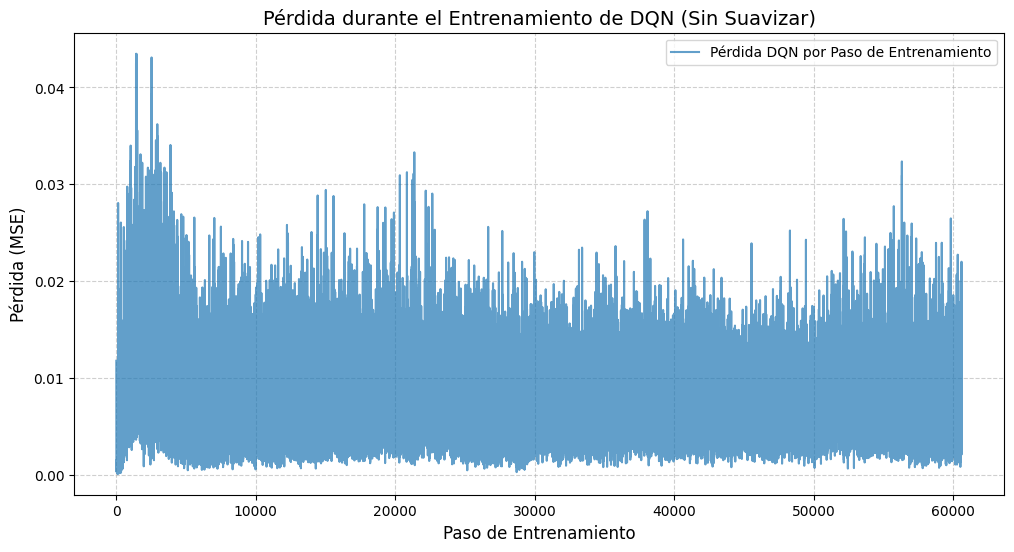

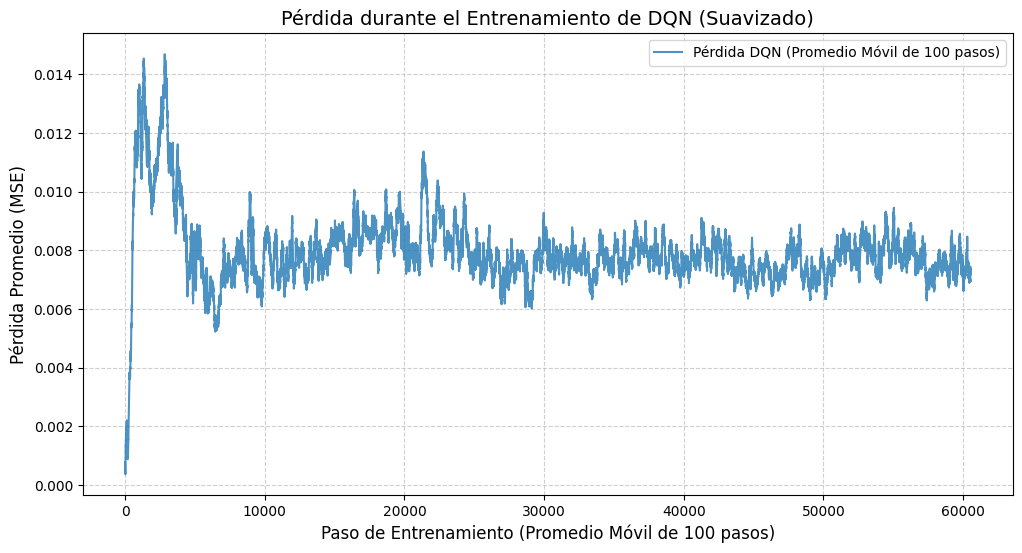

In [ ]:
# prompt: Graficar agente_dqn.losses que representa la pérdida durante el entrenamiento de DQN. Mostrar con y sin promedio móvil

"""
Este código sirve para visualizar cómo evoluciona el error (Loss) de la red neuronal DQN durante el entrenamiento.

Genera dos gráficos:
1. La pérdida original, mostrando cómo varía el error en cada paso de entrenamiento.
2. La pérdida suavizada mediante un promedio móvil de 100 pasos, para observar mejor su tendencia.
Recordemos que en DQN utilizamos una red neuronal para aproximar los valores Q. La pérdida mide la diferencia entre los valores Q que predice la red y los valores Q objetivo que debería aproximar.

¿Qué significa que la pérdida disminuya?
Significa que las predicciones de la red neuronal se están acercando a los valores Q objetivo utilizados durante el entrenamiento.

En general:
- Pérdida alta: existe una diferencia importante entre las predicciones y los objetivos.
- Pérdida baja: las predicciones están más cerca de los objetivos.
- Pérdida fluctuante: el error cambia entre las distintas actualizaciones.
Importante: una pérdida baja no garantiza que el agente llegue a la meta. Para evaluar si realmente aprendió a resolver FrozenLake debemos observar también la tasa de éxito.

"""

import matplotlib.pyplot as plt
# Graficar la pérdida del agente DQN
plt.figure(figsize=(12, 6))
plt.plot(agente_dqn.losses, label='Pérdida DQN por Paso de Entrenamiento', alpha=0.7)
plt.xlabel('Paso de Entrenamiento', fontsize=12)
plt.ylabel('Pérdida (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Sin Suavizar)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Graficar la pérdida con promedio móvil para suavizar
window_loss = 100 # Tamaño de la ventana para el promedio móvil de la pérdida
losses_dqn_suavizado = moving_average(agente_dqn.losses, window_loss)

plt.figure(figsize=(12, 6))
plt.plot(losses_dqn_suavizado, label=f'Pérdida DQN (Promedio Móvil de {window_loss} pasos)', alpha=0.8)
plt.xlabel(f'Paso de Entrenamiento (Promedio Móvil de {window_loss} pasos)', fontsize=12)
plt.ylabel('Pérdida Promedio (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Suavizado)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

#Interpretación de los gráficos: Pérdida durante el entrenamiento de DQN
Estos gráficos muestran cómo fue evolucionando el error de la red neuronal DQN durante el entrenamiento.

Recordemos que la pérdida (Loss) se calcula utilizando MSE (Error Cuadrático Medio), comparando los valores Q que predice la red principal con los valores Q objetivo calculados utilizando la Target Network.

La conclusión principal es que la pérdida presenta fluctuaciones importantes al principio, luego disminuye y se mantiene relativamente estable, aunque continúa variando durante el entrenamiento.

#1. Primer gráfico: pérdida sin suavizar
Pérdida DQN por paso de entrenamiento

¿Qué observamos?
- Al principio: aparecen variaciones importantes y algunos picos de error que alcanzan aproximadamente 0.055.
- Durante los primeros pasos: la pérdida presenta fluctuaciones elevadas porque la red está comenzando a aprender y sus predicciones todavía tienen diferencias respecto de los valores objetivo.
- A medida que avanza el entrenamiento: los valores de pérdida tienden a ser menores.
- Hacia el final: el error continúa fluctuando, pero generalmente se mantiene en valores relativamente bajos.
¿Por qué aparecen tantos picos?

Porque en cada actualización la red utiliza un lote de experiencias diferentes. Como las experiencias y los valores objetivo van cambiando, también puede cambiar el error calculado.

#2. Segundo gráfico: pérdida suavizada
Este gráfico utiliza un promedio móvil de 100 pasos para reducir las variaciones individuales.

Es más sencillo observar la tendencia general.

¿Qué podemos interpretar?
- Al comienzo, la pérdida aumenta hasta alcanzar aproximadamente 0.020.
- Después disminuye considerablemente.
- A partir de aproximadamente los 5.000 pasos, se mantiene generalmente entre 0.006 y 0.009.
- Hacia el final continúa presentando pequeñas fluctuaciones, pero no muestra una tendencia de crecimiento sostenido.
Esto indica que la red está consiguiendo aproximar los valores Q objetivo con un error relativamente bajo y estable.

#3. ¿Significa que DQN aprendió correctamente?
Los gráficos muestran que la pérdida se estabiliza en valores relativamente bajos. Esto es una señal favorable para el entrenamiento de la red neuronal.

Sin embargo, hay algo importante que debemos diferenciar:
- Loss: mide el error entre los valores Q predichos y los valores Q objetivo.
- Tasa de éxito: mide cuántas veces el agente consigue llegar a la meta.
Por lo tanto, una pérdida baja no garantiza que el agente resuelva correctamente FrozenLake.

Para comprobarlo debemos considerar también la tasa de éxito que obtuvimos anteriormente: DQN consiguió un 60,3%, mientras que Q-Learning alcanzó un 73%.

#Interpretación de la pérdida durante el entrenamiento de DQN

Los gráficos muestran la evolución de la pérdida (Loss) de la red neuronal DQN durante el entrenamiento.

En el primer gráfico, correspondiente a la pérdida sin suavizar, se observan numerosas fluctuaciones y algunos picos elevados, especialmente durante las primeras etapas del entrenamiento. Estas variaciones se producen porque la red entrena con diferentes lotes de experiencias y los valores Q objetivo van cambiando.

En el segundo gráfico se aplica un promedio móvil de 100 pasos, lo que permite observar mejor la tendencia general. Se aprecia que, después de un incremento inicial, la pérdida disminuye y posteriormente se mantiene relativamente estable, con pequeñas fluctuaciones.

Esto indica que la red neuronal consigue aproximar progresivamente los valores Q objetivo con un error menor.

En conclusión, la evolución de la pérdida muestra un comportamiento favorable durante el entrenamiento de DQN. Sin embargo, la pérdida por sí sola no determina si el agente aprendió a resolver el entorno. Para evaluar su rendimiento también debemos considerar la tasa de éxito obtenida durante las pruebas, que en esta experiencia fue del 60,3%.

# Ejercitación

## A) Modifique el entrenamiento de los agentes para entrenar por más episodios. Evalue su desempeño. ¿ Mejora o empeora ?






# Q-Learning Tabular

In [ ]:
# Crear nuevamente el agente Q-Learning
agente_qlearning_episodios = QLearningTabular(
    env.observation_space.n,
    env.action_space.n,
    lr=0.1,
    gamma=0.95,
    epsilon=1.0
)

# Aumentar el entrenamiento a 10.000 episodios
recompensas_qlearning_episodios = agente_qlearning_episodios.entrenar(
    env,
    episodios=10000
)

🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 2000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 3000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 4000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 5000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 6000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 7000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 8000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 9000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010
Episodio 10000: Tasa éxito (últimos 100) = 0.000, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!


#Deep Q-Network (DQN)

In [ ]:
# Crear nuevamente el agente DQN
agente_dqn_episodios = DQNAgent(
    env.observation_space.n,
    env.action_space.n,
    lr=0.001,
    gamma=0.95,
    epsilon=1.0
)

# Aumentar el entrenamiento a 10.000 episodios
recompensas_dqn_episodios = agente_dqn_episodios.entrenar(
    env,
    episodios=10000
)

🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.070, Epsilon = 0.367, Loss = 0.0105
Episodio 400: Tasa éxito = 0.230, Epsilon = 0.135, Loss = 0.0055
Episodio 600: Tasa éxito = 0.390, Epsilon = 0.049, Loss = 0.0107
Episodio 800: Tasa éxito = 0.470, Epsilon = 0.018, Loss = 0.0072
Episodio 1000: Tasa éxito = 0.610, Epsilon = 0.010, Loss = 0.0085
Episodio 1200: Tasa éxito = 0.590, Epsilon = 0.010, Loss = 0.0073
Episodio 1400: Tasa éxito = 0.600, Epsilon = 0.010, Loss = 0.0074
Episodio 1600: Tasa éxito = 0.500, Epsilon = 0.010, Loss = 0.0077
Episodio 1800: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0078
Episodio 2000: Tasa éxito = 0.390, Epsilon = 0.010, Loss = 0.0073
Episodio 2200: Tasa éxito = 0.620, Epsilon = 0.010, Loss = 0.0077
Episodio 2400: Tasa éxito = 0.540, Epsilon = 0.010, Loss = 0.0077
Episodio 2600: Tasa éxito = 0.590, Epsilon = 0.010, Loss = 0.0080
Episodio 2800: Tasa éxito = 0.540, Epsilon = 0.010, Loss = 0.0067
Episodio 3000: T

#Evaluar el desempeño de los agentes

In [ ]:
# Evaluar Q-Learning
tasa_exito_qlearning_episodios, _ = agente_qlearning_episodios.evaluar(
    env,
    episodios=1000
)

# Evaluar DQN
tasa_exito_dqn_episodios, _ = agente_dqn_episodios.evaluar(
    env,
    episodios=1000
)

📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.000
Pasos promedio: 17.2
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.704
Pasos promedio: 40.9


#Comparar los resultados

In [ ]:
# Comparación de resultados originales y nuevos

print("COMPARACIÓN DE RESULTADOS")
print("=" * 55)

print(f"Q-Learning anterior (1.000 episodios): {tasa_exito_qlearning:.3f}")
print(f"Q-Learning nuevo (10.000 episodios): {tasa_exito_qlearning_episodios:.3f}")

print("-" * 55)

print(f"DQN anterior (2.000 episodios): {tasa_exito_dqn:.3f}")
print(f"DQN nuevo (10.000 episodios): {tasa_exito_dqn_episodios:.3f}")

print("=" * 55)

COMPARACIÓN DE RESULTADOS
Q-Learning anterior (1.000 episodios): 0.725
Q-Learning nuevo (10.000 episodios): 0.000
-------------------------------------------------------
DQN anterior (2.000 episodios): 0.702
DQN nuevo (10.000 episodios): 0.704


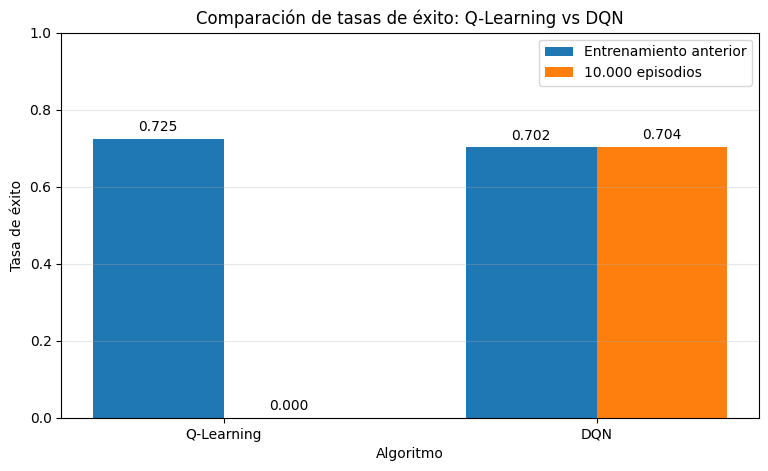

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

agentes = ["Q-Learning", "DQN"]

resultados_anteriores = [
    tasa_exito_qlearning,
    tasa_exito_dqn
]

resultados_nuevos = [
    tasa_exito_qlearning_episodios,
    tasa_exito_dqn_episodios
]

x = np.arange(len(agentes))
ancho = 0.35

plt.figure(figsize=(9, 5))

barras1 = plt.bar(
    x - ancho/2,
    resultados_anteriores,
    ancho,
    label="Entrenamiento anterior"
)

barras2 = plt.bar(
    x + ancho/2,
    resultados_nuevos,
    ancho,
    label="10.000 episodios"
)

plt.title("Comparación de tasas de éxito: Q-Learning vs DQN")
plt.ylabel("Tasa de éxito")
plt.xlabel("Algoritmo")
plt.xticks(x, agentes)
plt.ylim(0, 1)
plt.legend()

for barras in [barras1, barras2]:
    for barra in barras:
        valor = barra.get_height()
        plt.text(
            barra.get_x() + barra.get_width()/2,
            valor + 0.02,
            f"{valor:.3f}",
            ha="center"
        )

plt.grid(axis="y", alpha=0.3)
plt.show()

#¿Cómo interpretar los resultados?


- Si la tasa de éxito aumenta: el agente mejoró su desempeño. Los episodios adicionales permitieron aprender una mejor estrategia.
- Si la tasa de éxito se mantiene: el agente probablemente ya había alcanzado un nivel de aprendizaje relativamente estable.
- Si la tasa de éxito disminuye: entrenar más no garantizó una mejora. Puede deberse a la variabilidad del entorno, la exploración o la configuración del algoritmo.
Es importante recordar que FrozenLake tiene movimientos resbaladizos (is_slippery=True). Por eso, aunque el agente aprenda una buena política, no siempre conseguirá llegar a la meta.

#Conclusion


Al aumentar la cantidad de episodios de entrenamiento, los resultados fueron diferentes para cada algoritmo.

- Q-Learning: el rendimiento empeoró considerablemente. Con 1.000 episodios obtuvo una tasa de éxito del 72,5 %, mientras que con 10.000 episodios obtuvo un 0 %. Por lo tanto, en este experimento, aumentar los episodios no mejoró el aprendizaje del agente.

- DQN: el rendimiento se mantuvo prácticamente estable. Con 2.000 episodios obtuvo un 70,2 % de éxito y con 10.000 episodios alcanzó un 70,4 %. Esto representa una mejora mínima de 0,2 puntos porcentuales, por lo que no se observa una mejora significativa.

Conclusión general: aumentar la cantidad de episodios no garantiza un mejor rendimiento de los algoritmos de aprendizaje por refuerzo. En nuestros experimentos, DQN mantuvo resultados estables, mientras que Q-Learning presentó un empeoramiento importante. Esto demuestra que el desempeño no depende únicamente de la cantidad de episodios, sino también de los hiperparámetros, la estrategia de exploración y las características del entorno.








## B) Considere modificar el modelo DQN el hiperparámetro gamma: un valor bajo, uno medio y uno alto. Entrene los tres modelos y compare los resultados. Comparta sus conclusiones

In [ ]:
#en DQN, gamma es el factor de descuento de las recompensas futuras

# Experimento: comparación del hiperparámetro Gamma
# Definimos tres valores de gamma
valores_gamma = {
    "Gamma bajo": 0.1,
    "Gamma medio": 0.5,
    "Gamma alto": 0.99
}

# Mantenemos la misma cantidad de episodios para los tres modelos
episodios_entrenamiento = 2000
episodios_evaluacion = 1000

In [ ]:
#Qué hace este código?
#1. Crea un agente nuevo con gamma 0.1 y lo entrena.
#2. Evalúa su rendimiento durante 1.000 episodios.
#. Repite el procedimiento con gamma 0.5.
#. Repite nuevamente con gamma 0.99.
##. Guarda los resultados para compararlos.
#Cada agente comienza con una red neuronal nueva, una memoria de experiencias vacía y sus propios parámetros.


#Entrenar y evaluar los tres modelos DQN



# Diccionario para almacenar los resultados
resultados_gamma = {}

# Ejecutamos los tres experimentos
for nombre, gamma in valores_gamma.items():

    print("\n" + "=" * 55)
    print(f"EXPERIMENTO: {nombre} - Gamma = {gamma}")
    print("=" * 55)

    # Fijamos las semillas para facilitar una comparación reproducible
    semilla = 42

    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)

    # Reiniciamos el entorno con la misma semilla
    env.reset(seed=semilla)

    # Creamos un agente DQN nuevo para cada valor de gamma
    agente = DQNAgent(
        env.observation_space.n,
        env.action_space.n,
        lr=0.001,
        gamma=gamma,
        epsilon=1.0
    )

    # Entrenamos el agente
    recompensas_entrenamiento = agente.entrenar(
        env,
        episodios=episodios_entrenamiento
    )

    # Reiniciamos la semilla antes de evaluar
    env.reset(seed=semilla + 1000)

    # Evaluamos el agente sin exploración
    tasa_exito, recompensas_eval = agente.evaluar(
        env,
        episodios=episodios_evaluacion
    )

    # Guardamos los resultados
    resultados_gamma[nombre] = {
        "Gamma": gamma,
        "Tasa de éxito": tasa_exito,
        "Recompensa promedio": np.mean(recompensas_eval)
    }

    print(f"\nResultado {nombre}:")
    print(f"Tasa de éxito: {tasa_exito:.3f}")
    print(f"Recompensa promedio: {np.mean(recompensas_eval):.3f}")

print("\nExperimentos finalizados.")


EXPERIMENTO: Gamma bajo - Gamma = 0.1
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.010, Epsilon = 0.367, Loss = 0.0010
Episodio 400: Tasa éxito = 0.020, Epsilon = 0.135, Loss = 0.0027
Episodio 600: Tasa éxito = 0.040, Epsilon = 0.049, Loss = 0.0024
Episodio 800: Tasa éxito = 0.090, Epsilon = 0.018, Loss = 0.0026
Episodio 1000: Tasa éxito = 0.050, Epsilon = 0.010, Loss = 0.0033
Episodio 1200: Tasa éxito = 0.050, Epsilon = 0.010, Loss = 0.0025
Episodio 1400: Tasa éxito = 0.040, Epsilon = 0.010, Loss = 0.0043
Episodio 1600: Tasa éxito = 0.090, Epsilon = 0.010, Loss = 0.0027
Episodio 1800: Tasa éxito = 0.030, Epsilon = 0.010, Loss = 0.0044
Episodio 2000: Tasa éxito = 0.030, Epsilon = 0.010, Loss = 0.0036

✅ Entrenamiento Deep Q-Network (DQN) completado!
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.000
Pasos promedio: 17.9

Resultado Gamma bajo:
Tasa de éxito: 0.000
Recompensa promedio: 0.000

EXPERIMENTO: Gamma medio - Gamma = 0.5
🖥️

In [ ]:
#Mostrar la tabla comparativa
# Convertimos los resultados en un DataFrame
df_gamma = pd.DataFrame(resultados_gamma).T

# Mostramos la comparación
display(df_gamma)

,Gamma,Tasa de éxito,Recompensa promedio
Gamma bajo,0.10,0.00,0.00
Gamma medio,0.50,0.00,0.00
Gamma alto,0.99,0.75,0.75


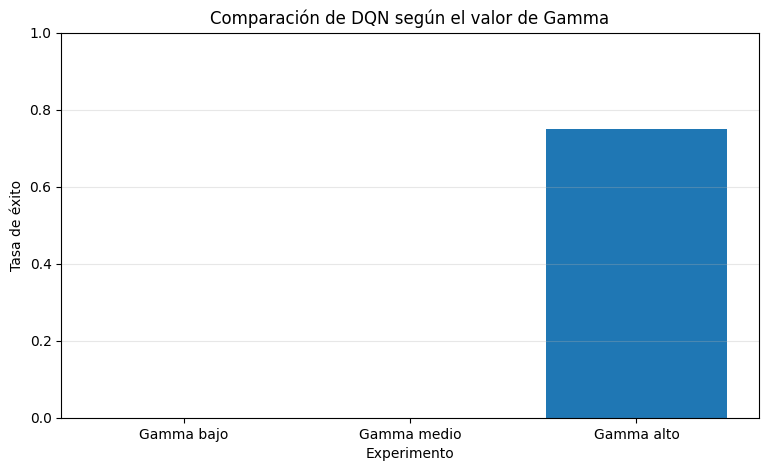

In [ ]:
#Generar un gráfico comparativo


plt.figure(figsize=(9, 5))

plt.bar(
    df_gamma.index,
    df_gamma["Tasa de éxito"]
)

plt.title("Comparación de DQN según el valor de Gamma")
plt.xlabel("Experimento")
plt.ylabel("Tasa de éxito")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

#Experimento: modificación del hiperparámetro Gamma en DQN

Se realizaron tres entrenamientos utilizando el algoritmo Deep Q-Network (DQN), modificando el hiperparámetro gamma y manteniendo constantes los demás parámetros del modelo.

##Se probaron los siguientes valores:

- Gamma bajo: 0.1.

- Gamma medio: 0.5.

- Gamma alto: 0.99.

El objetivo fue analizar cómo influye el factor de descuento en la importancia que el agente asigna a las recompensas futuras.

Cada modelo fue entrenado durante 2.000 episodios y posteriormente evaluado durante 1.000 episodios, utilizando la tasa de éxito y la recompensa promedio como métricas de comparación.

###Análisis de resultados:

- Gamma bajo (0.1): el agente obtuvo un 0 % de éxito. Al utilizar un factor de descuento bajo, prioriza las recompensas inmediatas y considera poco las recompensas futuras. Esto dificulta aprender una estrategia para llegar a la meta.

- Gamma medio (0.5): también obtuvo un 0 % de éxito. Aunque considera más las recompensas futuras que el valor anterior, no consiguió aprender una política efectiva durante los 2.000 episodios.

- Gamma alto (0.99): obtuvo un 75 % de éxito y una recompensa promedio de 0.75. Al considerar más las recompensas futuras, consiguió aprender una estrategia mucho más efectiva para alcanzar la meta.

###Conclusión:

A partir de los experimentos realizados, se observa que el hiperparámetro gamma tuvo una influencia importante en el rendimiento del agente DQN.

Los valores bajos (0.1) y medios (0.5) obtuvieron una tasa de éxito del 0 %, mientras que el valor alto (0.99) alcanzó un 75 % de éxito durante la evaluación.

Esto indica que, en el entorno FrozenLake utilizado, considerar las recompensas futuras fue fundamental para que el agente pudiera aprender una estrategia efectiva y alcanzar la meta.

Por lo tanto, entre los tres valores probados, gamma = 0.99 fue el que produjo el mejor rendimiento. Este resultado demuestra que el valor de gamma puede influir significativamente en el aprendizaje de un agente de aprendizaje por refuerzo, aunque un valor alto no garantiza necesariamente mejores resultados en todos los entornos.

## C) Lo mismo que en B) pero para el hiperparámetro alpha.

In [ ]:
# Experimento: comparación del hiperparámetro Alpha
#alpha está representado por el parámetro lr, que se utiliza en el optimizador Adam

valores_alpha = {
    "Alpha bajo": 0.0001,
    "Alpha medio": 0.001,
    "Alpha alto": 0.01
}

# Mantenemos la misma cantidad de episodios
episodios_entrenamiento = 2000
episodios_evaluacion = 1000

In [ ]:
#Entrenar y evaluar los tres modelos


# Diccionario para guardar los resultados
resultados_alpha = {}

# Recorremos los tres valores de alpha
for nombre, alpha in valores_alpha.items():

    print("\n" + "=" * 55)
    print(f"EXPERIMENTO: {nombre} - Alpha = {alpha}")
    print("=" * 55)

    # Fijamos las semillas
    semilla = 42

    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)

    # Reiniciamos el entorno
    env.reset(seed=semilla)

    # Creamos un agente DQN nuevo
    agente = DQNAgent(
        env.observation_space.n,
        env.action_space.n,
        lr=alpha,       # Modificamos Alpha
        gamma=0.95,     # Mantenemos Gamma constante
        epsilon=1.0
    )

    # Entrenamos el modelo
    recompensas_entrenamiento = agente.entrenar(
        env,
        episodios=episodios_entrenamiento
    )

    # Preparamos la evaluación
    env.reset(seed=semilla + 1000)

    # Evaluamos el agente sin exploración
    tasa_exito, recompensas_eval = agente.evaluar(
        env,
        episodios=episodios_evaluacion
    )

    # Guardamos los resultados
    resultados_alpha[nombre] = {
        "Alpha": alpha,
        "Tasa de éxito": tasa_exito,
        "Recompensa promedio": np.mean(recompensas_eval)
    }

    print(f"\nResultado {nombre}:")
    print(f"Tasa de éxito: {tasa_exito:.3f}")
    print(f"Recompensa promedio: {np.mean(recompensas_eval):.3f}")

print("\nExperimentos finalizados.")


EXPERIMENTO: Alpha bajo - Alpha = 0.0001
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.060, Epsilon = 0.367, Loss = 0.0072
Episodio 400: Tasa éxito = 0.260, Epsilon = 0.135, Loss = 0.0075
Episodio 600: Tasa éxito = 0.450, Epsilon = 0.049, Loss = 0.0080
Episodio 800: Tasa éxito = 0.560, Epsilon = 0.018, Loss = 0.0081
Episodio 1000: Tasa éxito = 0.470, Epsilon = 0.010, Loss = 0.0087
Episodio 1200: Tasa éxito = 0.630, Epsilon = 0.010, Loss = 0.0077
Episodio 1400: Tasa éxito = 0.600, Epsilon = 0.010, Loss = 0.0081
Episodio 1600: Tasa éxito = 0.660, Epsilon = 0.010, Loss = 0.0076
Episodio 1800: Tasa éxito = 0.590, Epsilon = 0.010, Loss = 0.0083
Episodio 2000: Tasa éxito = 0.620, Epsilon = 0.010, Loss = 0.0079

✅ Entrenamiento Deep Q-Network (DQN) completado!
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.734
Pasos promedio: 40.2

Resultado Alpha bajo:
Tasa de éxito: 0.734
Recompensa promedio: 0.734

EXPERIMENTO: Alpha medio - Alpha = 0.0

In [ ]:
#Mostrar la tabla comparativa
# Convertimos los resultados en una tabla
df_alpha = pd.DataFrame(resultados_alpha).T

# Mostramos los resultados
display(df_alpha)


,Alpha,Tasa de éxito,Recompensa promedio
Alpha bajo,0.0001,0.734,0.734
Alpha medio,0.0010,0.734,0.734
Alpha alto,0.0100,0.000,0.000


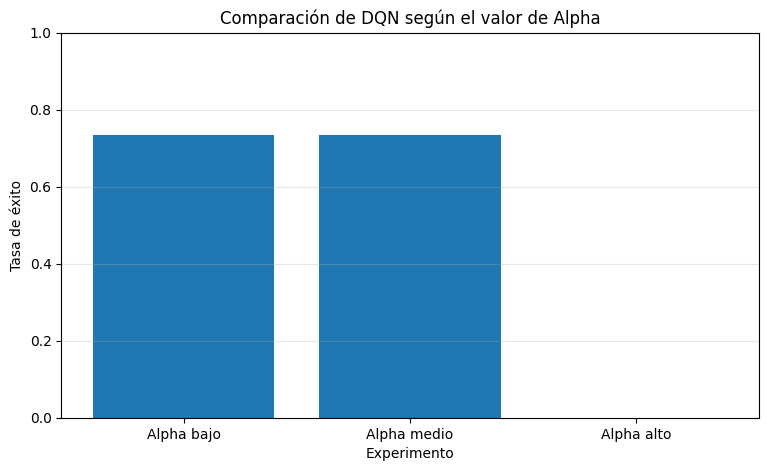

In [ ]:
#Generar un gráfico comparativo
plt.figure(figsize=(9, 5))

plt.bar(
    df_alpha.index,
    df_alpha["Tasa de éxito"]
)

plt.title("Comparación de DQN según el valor de Alpha")
plt.xlabel("Experimento")
plt.ylabel("Tasa de éxito")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

#Experimento: modificación del hiperparámetro Alpha en DQN

Se realizaron tres entrenamientos utilizando el algoritmo Deep Q-Network (DQN), modificando el hiperparámetro alpha (tasa de aprendizaje) y manteniendo constantes los demás parámetros del modelo.

###Se probaron los siguientes valores:

- Alpha bajo: 0.0001.

- Alpha medio: 0.001.

- Alpha alto: 0.01.

El objetivo fue analizar cómo influye la tasa de aprendizaje en la actualización de los pesos de la red neuronal.

Cada modelo fue entrenado durante 2.000 episodios y posteriormente evaluado durante 1.000 episodios. Para comparar su desempeño se utilizaron la tasa de éxito y la recompensa promedio.

###Análisis de resultados:

Los resultados obtenidos fueron los siguientes:

- Alpha bajo (0.0001): alcanzó una tasa de éxito del 73,4 %.

- Alpha medio (0.001): también alcanzó una tasa de éxito del 73,4 %.

- Alpha alto (0.01): obtuvo una tasa de éxito del 0 %.

Se observa que los valores bajo y medio consiguieron el mismo rendimiento durante la evaluación, mientras que el valor alto no logró aprender una política efectiva.

###Conclusión:

El experimento demuestra que el hiperparámetro alpha influye en el rendimiento del agente DQN. Los valores 0.0001 y 0.001 obtuvieron los mejores resultados, con una tasa de éxito del 73,4 %, mientras que el valor 0.01 presentó un rendimiento inferior, con un 0 % de éxito.

Esto permite observar que una tasa de aprendizaje demasiado elevada puede provocar actualizaciones excesivas en los pesos de la red neuronal y dificultar el aprendizaje.

En conclusión, entre los tres valores evaluados, alpha = 0.0001 y alpha = 0.001 fueron los más adecuados para este experimento. Los resultados muestran que una tasa de aprendizaje más alta no garantiza un mejor rendimiento.